# A Transformer-Based Approach for Raw EEG Classification

## 1. Setup and Imports

Import necessary libraries and set up the environment.



In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [2]:
import numpy as np
from pathlib import Path
import re
import sys
import random

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from datapreprocessing import EEGpreprocessing, EEGDataset
from train import  EEGTrainer
from models import F_CTrans , F_CTrans_modified


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

## 2. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [3]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorImagery(04,08,012)") 

print(f"Dataset path used: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")


Dataset path used: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Subject Processing {subj_id} - File: {file_path}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
    except Exception as e:
        print(f"❌ ERROR: Unable to read Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=0.5, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Subject {subj_id}. Jump.")
        continue
    
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch', verbose=False)
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,
        'psd_data': psd_values,
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2))
    })

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    # Label extraction and mapping (Left = 0, Right = 1)
    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

   
    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_raw_list)}")

Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
N

/tmp/ipykernel_823345/1209130614.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
10 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 10 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R08.edf


/tmp/ipykernel_823345/1209130614.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 eve

/tmp/ipykernel_823345/1209130614.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


... (3 outputs left out)

/tmp/ipykernel_823345/1209130614.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
/tmp/ipykernel_823345/1209130614.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 100 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S100/S100R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R04.edf


/tmp/ipykernel_823345/1209130614.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 e

In [5]:

X_test_raw_list = []
y_test_list = []
test_subject_ids_list = []


for i, rec in enumerate(test_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Processing Test Subject {subj_id} - File: {file_path.name}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')
    except Exception as e:
        print(f"❌ ERROR: Unable to read Test Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=0.5, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Test Subject {subj_id}. Jump.")
        continue

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

    X_test_raw_list.append(X_raw)
    y_test_list.append(labels)
    test_subject_ids_list.extend([subj_id] * len(X_raw))




print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_test_raw_list)}")

Processing Test Subject 5 - File: S005R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 5 - File: S005R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 5 - File: S005R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 11 - File: S011R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not

Convert to PyTorch tensors

In [6]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Shape X_train_val : {X_training_validation_raw.shape}")
print(f"Shape y_train_val: {y_training_validation.shape}")
print("Label distribution:", np.unique(y_training_validation, return_counts=True))


X_test_raw = np.concatenate(X_test_raw_list, axis=0)
y_test = np.concatenate(y_test_list, axis=0)
test_subject_ids = np.array(test_subject_ids_list)


print(f"Shape X_test : {X_test_raw.shape}")
print(f"Shape y_test: {y_test.shape}")
print("Label distribution:", np.unique(y_test, return_counts=True))

Shape X_train_val : (4370, 64, 641)
Shape y_train_val: (4370,)
Label distribution: (array([0, 1]), array([2205, 2165]))
Shape X_test : (495, 64, 641)
Shape y_test: (495,)
Label distribution: (array([0, 1]), array([249, 246]))


##  Cross-Individual 5-Fold Cross-Validation



### f_CTrans with MultiStepLR 

In this section I implement the f_CTrans of the blabla article using the information in section "C. Training Setup"  and in "Table I", I emphasize the use of the MultiStepLR as scheduler

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.78829, train_acc=49.70%, val_loss=0.70035, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.67170, train_acc=54.81%, val_loss=0.54863, val_acc=74.41% | LR: 0.001000
Epoch 03/50: train_loss=0.47569, train_acc=75.97%, val_loss=0.43369, val_acc=78.35% | LR: 0.001000
Epoch 04/50: train_loss=0.40536, train_acc=80.94%, val_loss=0.42877, val_acc=80.16% | LR: 0.001000
Epoch 05/50: train_loss=0.37810, train_acc=82.26%, val_loss=0.42730, val_acc=79.14% | LR: 0.001000
Epoch 06/50: train_loss=0.36413, train_acc=83.35%, val_loss=0.41127, val_acc=80.72% | LR: 0.001000
Epoch 07/50: train_loss=0.33324, train_acc=84.93%, val_loss=0.40168, val_acc=82.41% | LR: 0.001000
Epoch 08/50: train_loss=0.32840, train_acc=85.21%, val_loss=0.37079, val_acc=83.20% | LR: 0.001000
Epoch 09/50: train_loss=0.31253, train_acc=84.84%, val_loss=0.40140, val_acc=82.30% | LR: 0.

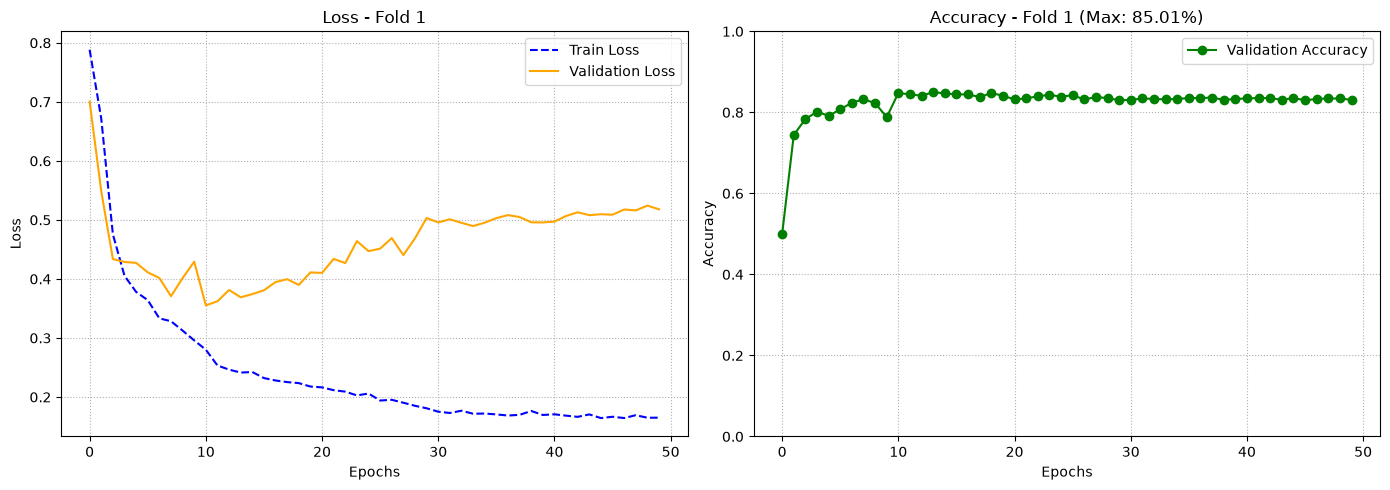


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 85.01% (± 0.00%)


In [7]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.79690, train_acc=50.07%, val_loss=0.77442, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.70852, train_acc=50.85%, val_loss=0.62649, val_acc=67.98% | LR: 0.001000
Epoch 03/50: train_loss=0.51655, train_acc=73.30%, val_loss=0.43251, val_acc=78.13% | LR: 0.001000
Epoch 04/50: train_loss=0.40400, train_acc=80.30%, val_loss=0.40039, val_acc=80.50% | LR: 0.001000
Epoch 05/50: train_loss=0.37021, train_acc=82.26%, val_loss=0.38132, val_acc=82.41% | LR: 0.001000
Epoch 06/50: train_loss=0.37168, train_acc=82.00%, val_loss=0.38361, val_acc=81.06% | L

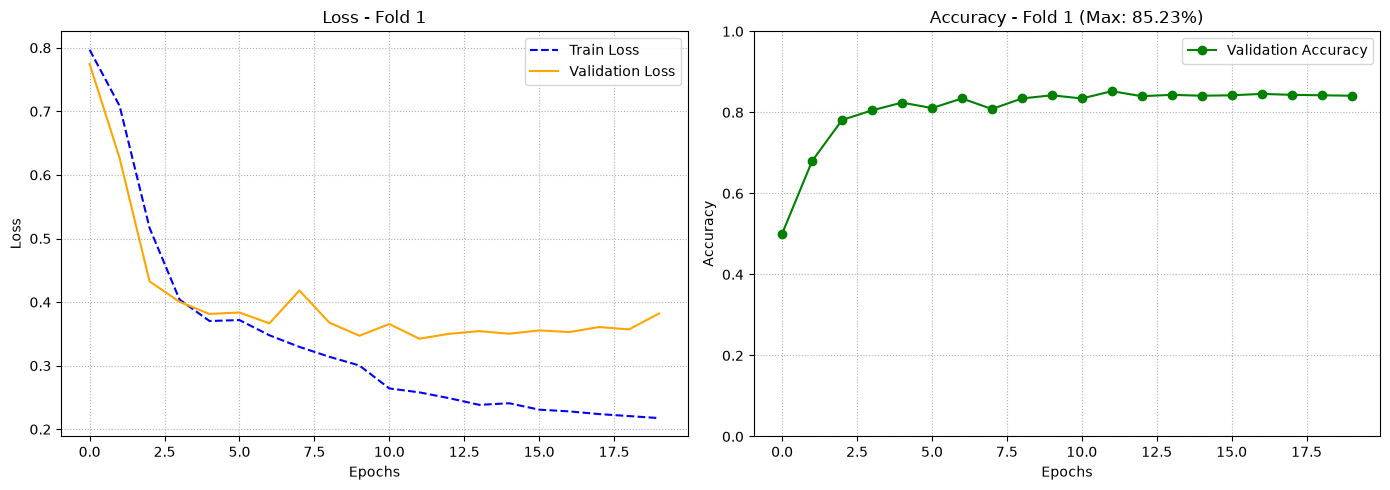


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 85.23% (± 0.00%)


In [11]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, patience=8 , scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.77662, train_acc=50.07%, val_loss=0.69882, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.70296, train_acc=49.76%, val_loss=0.73177, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.67701, train_acc=54.35%, val_loss=0.58662, val_acc=70.24% | LR: 0.001000
Epoch 04/50: train_loss=0.49155, train_acc=75.60%, val_loss=0.50735, val_acc=78.92% | LR: 0.001000
Epoch 05/50: train_loss=0.41663, train_acc=80.79%, val_loss=0.39033, val_acc=80.83% | LR: 0.001000
Epoch 06/50: train_loss=0.41142, train_acc=80.39%, val_loss=0.43881, val_acc=79.59% | L

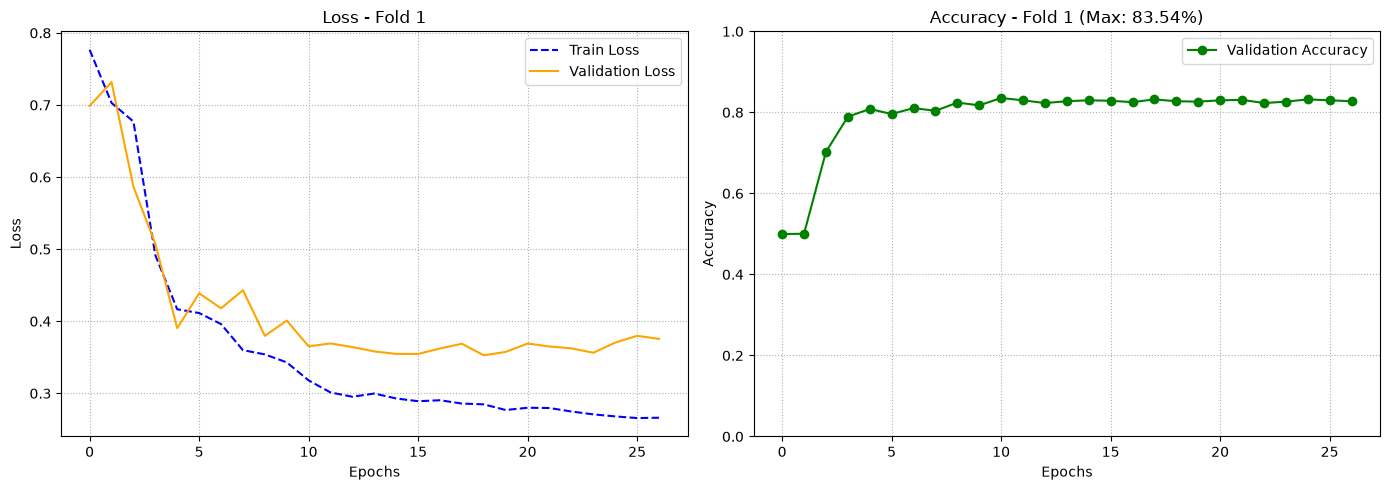


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 83.54% (± 0.00%)


In [15]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.5, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, patience=8 , scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans with ReduceLROnPlateau

In this section, visto lo stagnare della val_acc, ho cambiato lo scheduler per poter adattare il tasso di apprendimento in tempo reale

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.77472, train_acc=50.33%, val_loss=0.68729, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.57192, train_acc=67.70%, val_loss=0.44123, val_acc=78.47% | LR: 0.001000
Epoch 03/50: train_loss=0.41085, train_acc=80.10%, val_loss=0.39015, val_acc=82.75% | LR: 0.001000
Epoch 04/50: train_loss=0.36985, train_acc=82.80%, val_loss=0.37916, val_acc=82.41% | LR: 0.001000
Epoch 05/50: train_loss=0.35145, train_acc=83.41%, val_loss=0.43164, val_acc=80.27% | LR: 0.001000
Epoch 06/50: train_loss=0.35038, train_acc=83.89%, val_loss=0.36641, val_acc=83.65% | L

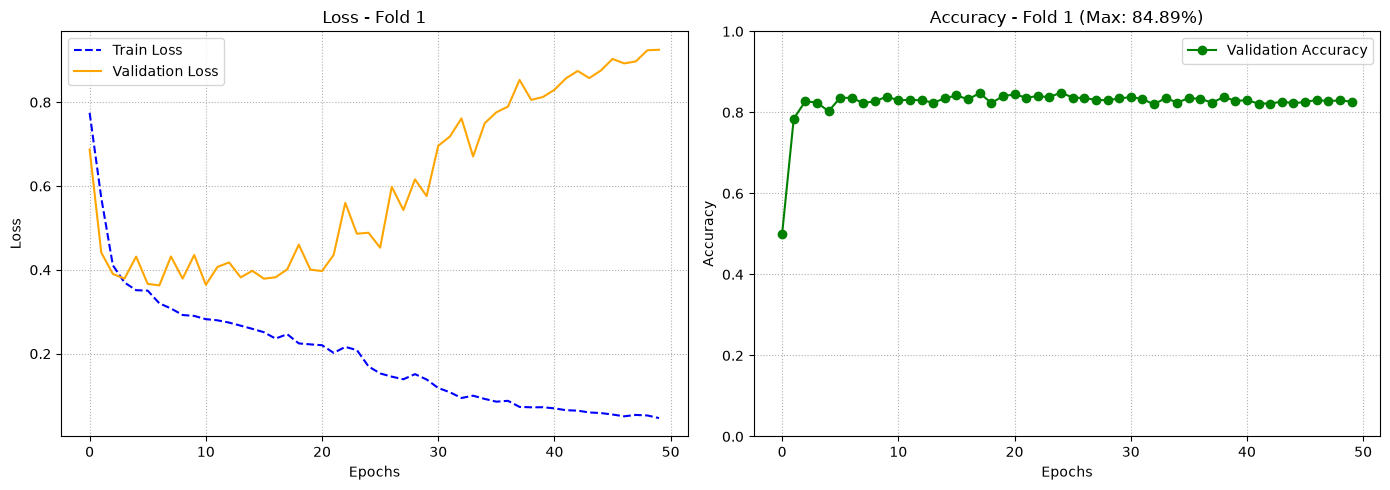


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 84.89% (± 0.00%)


In [8]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans_modified with MultiStepLR

scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Epoch 01/50: train_loss=0.72034, train_acc=50.76%, val_loss=0.69290, val_acc=50.85% | LR: 0.001000
Epoch 02/50: train_loss=0.69878, train_acc=49.50%, val_loss=0.69620, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69665, train_acc=50.22%, val_loss=0.69732, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69489, train_acc=51.39%, val_loss=0.68401, val_acc=57.84% | LR: 0.001000
Epoch 05/50: train_loss=0.65720, train_acc=61.53%, val_loss=0.58688, val_acc=69.11% | LR: 0.001000
Epoch 06/50: train_loss=0.54977, train_acc=72.90%, val_loss=0.46762, val_acc=78.35% | LR: 0.001000
Epoch 07/50: train_loss=0.45571, train_acc=78.29%, val_loss=0.47787, val_acc=77.56% | LR: 0.001000
Epoch 08/50: train_loss=0.42528, train_acc=80.30%, val_loss=0.40932, val_acc=81.29% | LR: 0.001000
Epoch 09/50: train_loss=0.39854, train_acc=81.40%, val_loss=0.43385, val_acc=79.37% | LR: 0.001000
Epoch 10/50: train_los

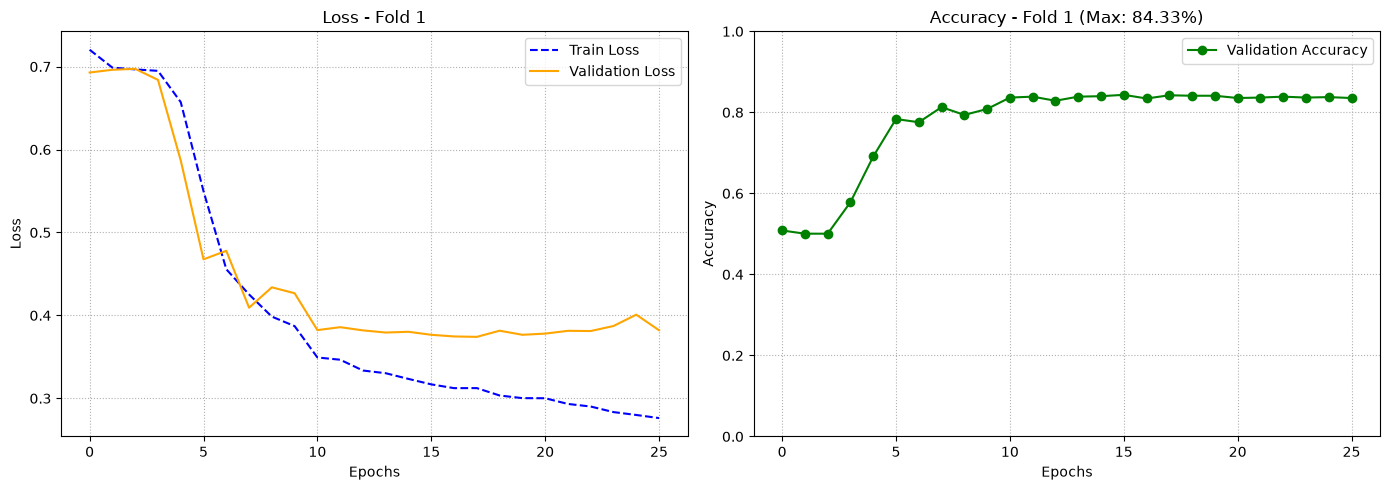


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 84.33% (± 0.00%)


In [9]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)  
    
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)


   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, patience = 8 ,scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### F_CTrans_modified with ReduceLROnPlateau

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.70812, train_acc=49.96%, val_loss=0.69783, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69558, train_acc=50.42%, val_loss=0.69294, val_acc=49.83% | LR: 0.001000
Epoch 03/50: train_loss=0.69298, train_acc=51.45%, val_loss=0.68556, val_acc=54.11% | LR: 0.001000
Epoch 04/50: train_loss=0.64293, train_acc=61.67%, val_loss=0.52719, val_acc=72.72% | LR: 0.001000
Epoch 05/50: train_loss=0.48231, train_acc=77.20%, val_loss=0.46954, val_acc=77.00% | LR: 0.001000
Epoch 06/50: train_loss=0.42606, train_acc=79.76%, val_loss=0.44566, val_acc=78.24% | L

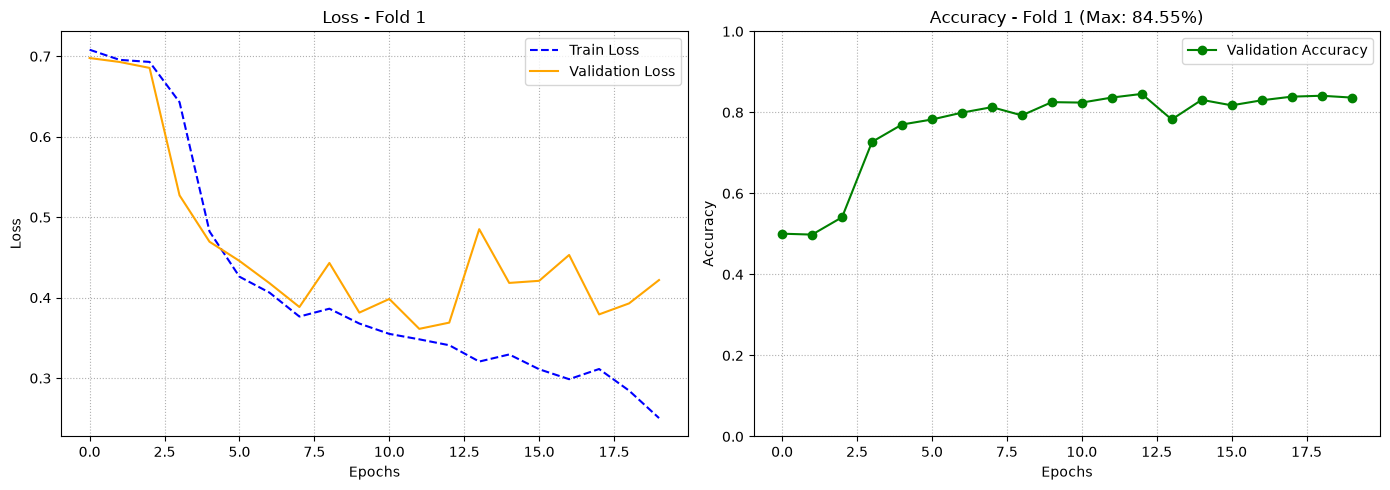


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 84.55% (± 0.00%)


In [10]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, patience= 8,  scheduler=scheduler)
 
    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

# grid search

In [18]:
from itertools import product
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Device configuration
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")

ALPHA_NOISE = 0.01
EPOCHS = 50 
EPSILON = 1e-8
BATCH_SIZE = 64

gkf = GroupKFold(n_splits=5)

param_grid = {
    'lr': [0.0005, 0.001],
    'weight_decay': [1e-4, 1e-3],
    'dropout': [0.3, 0.5]
}

keys = param_grid.keys()
combinations = list(product(*param_grid.values()))

print(f"Total combinations to test: {len(combinations)}")

best_overall_acc = 0.0
best_hyperparams = None

# Loop over all hyperparameter combinations
for idx, combo in enumerate(combinations):
    curr_lr, curr_wd, curr_dropout = combo
    
    print(f"TESTING CONFIG {idx + 1}/{len(combinations)}")
    print(f"LR: {curr_lr} | WD: {curr_wd} | Dropout: {curr_dropout}")
 
    
    fold_accuracies = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        if fold not in (0, 4):
            continue
            
        print(f"\n--- START TRAINING - FOLD {fold + 1}/5 ---")
        
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]
        
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

        X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
        noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
        
        model = F_CTrans(num_channels=64, d_model=128, nhead=8, d_ff=512, dropout=curr_dropout, num_layers=3, num_classes=2 ).to(device)
      
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=curr_lr, betas=(0.9, 0.95), weight_decay=curr_wd)
        scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
      
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

        best_val_acc, _, _, _ = trainer.train_and_validate_patience(
            train_loader=train_loader, 
            val_loader=val_loader, 
            epochs=EPOCHS, 
            patience=8, 
            scheduler=scheduler
        )

        fold_accuracies.append(best_val_acc)
        print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")
    
    mean_cv_acc = np.mean(fold_accuracies)
    print(f"👉 Configuration {idx + 1} average accuracy (Fold 1 & 5): {mean_cv_acc * 100:.2f}%")

    if mean_cv_acc > best_overall_acc:
        best_overall_acc = mean_cv_acc
        best_hyperparams = {
            'lr': curr_lr,
            'weight_decay': curr_wd,
            'dropout': curr_dropout
        }
        print(f"🎉 New best record found! Best average accuracy: {best_overall_acc * 100:.2f}%")
    
print(f" GRID SEARCH COMPLETED (ON FOLDS 1 & 5)!")
print(f" Best Hyperparameters found: {best_hyperparams}")
print(f" Best Average Accuracy (Folds 1 & 5): {best_overall_acc * 100:.2f}%")


Detected device: GPU NVIDIA (CUDA)
Total combinations to test: 8
TESTING CONFIG 1/8
LR: 0.0005 | WD: 0.0001 | Dropout: 0.3

--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.73734, train_acc=50.82%, val_loss=0.68704, val_acc=53.21% | LR: 0.000500
Epoch 02/50: train_loss=0.58132, train_acc=65.63%, val_loss=0.47371, val_acc=76.10% | LR: 0.000500
Epoch 03/50: train_loss=0.41476, train_acc=79.67%, val_loss=0.39614, val_acc=81.17% | LR: 0.000500
Epoch 04/50: train_loss=0.37920, train_acc=81.17%, val_loss=0.40845, val_acc=81.51% | LR: 0.000500
Epoch 05/50: train_loss=0.36171, train_acc=83.03%, val_loss=0.35421, val_acc=83.65% | LR: 0.000500
Epoch 06/50: train_loss=0.35194, train_acc=83.09%, val_loss=0.35888, val_acc=83.43% | LR: 0.000500
Epoch 07/50: train_loss=0.33556, train_acc=84.44%, val_loss=0.36859, val_acc=82.41% | LR: 0.000500
Epoch 08/50: train_loss=0.33046, train_acc=83.95%, val_loss=0.34972, val_acc=83.88% | LR: 0.000500
Epoch 09/50: train_loss=0.31243, train_acc=85.53%,

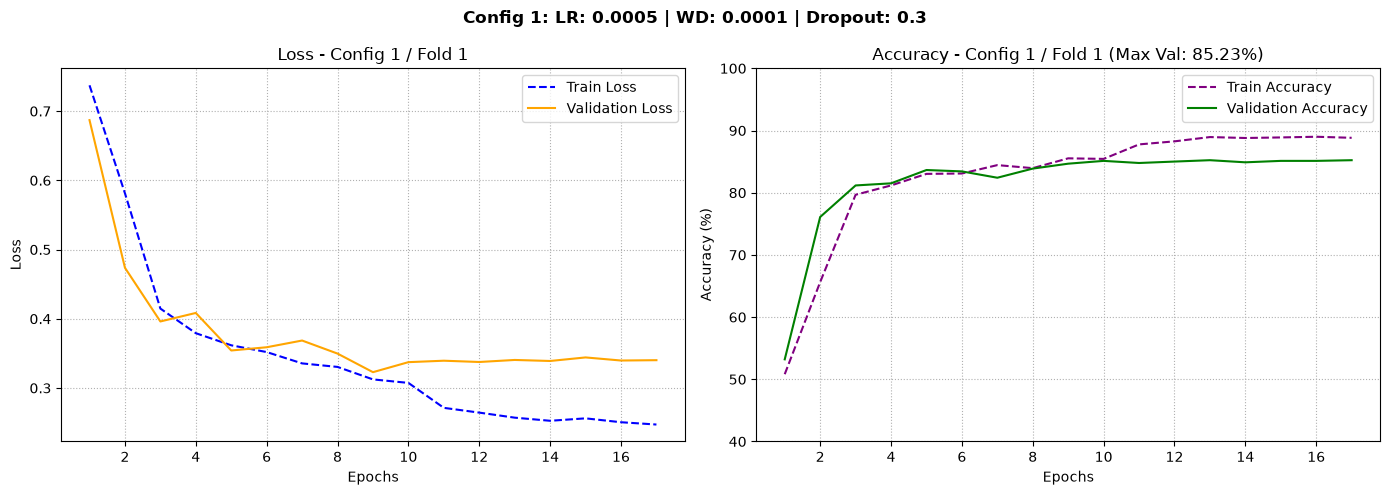

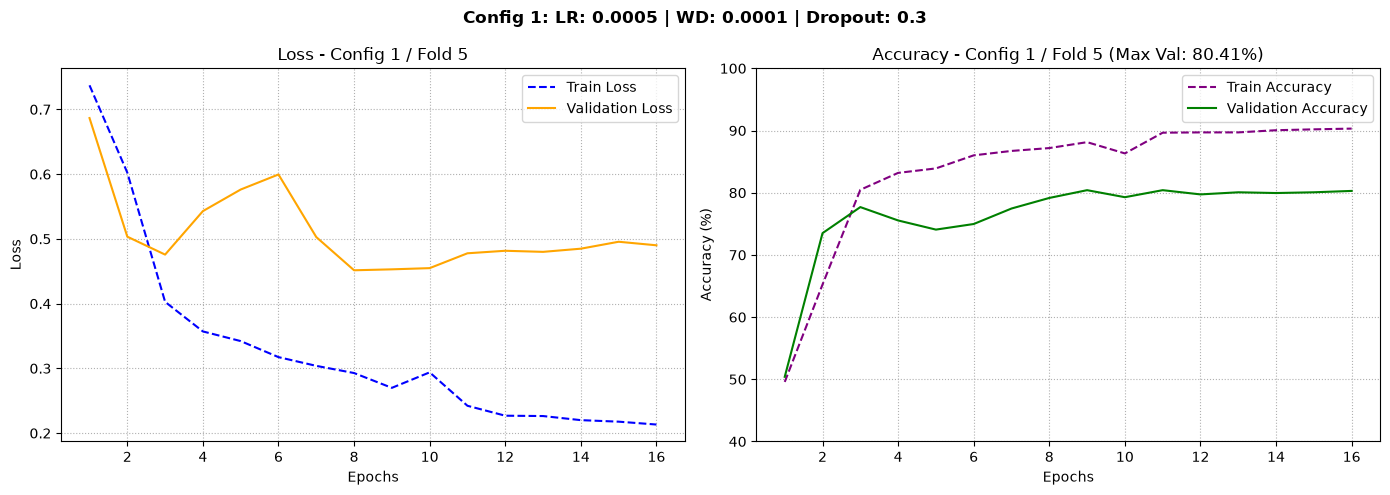

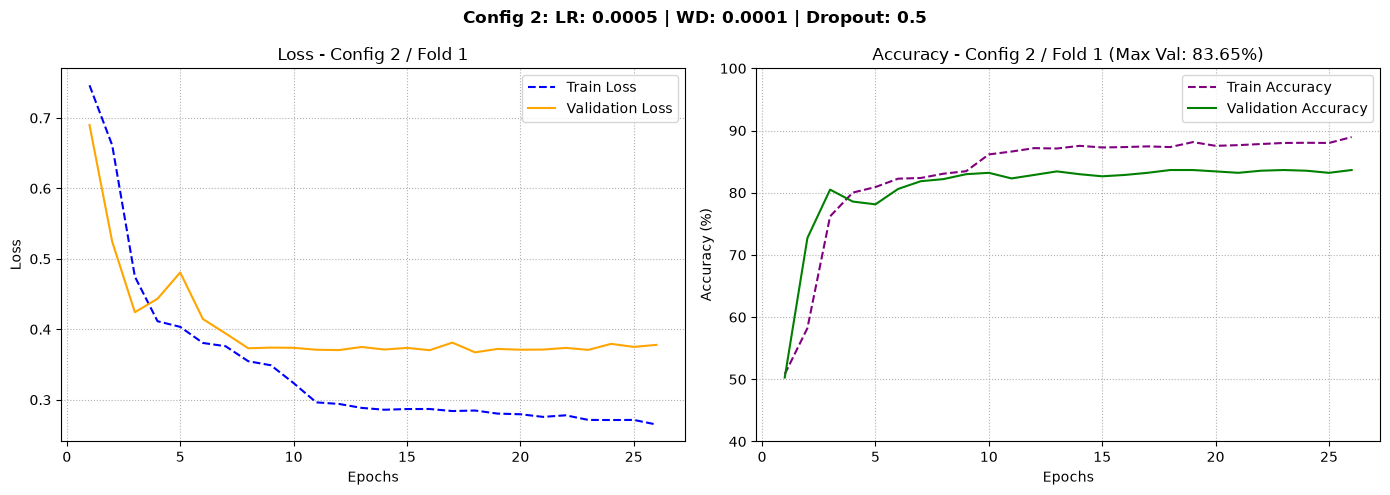

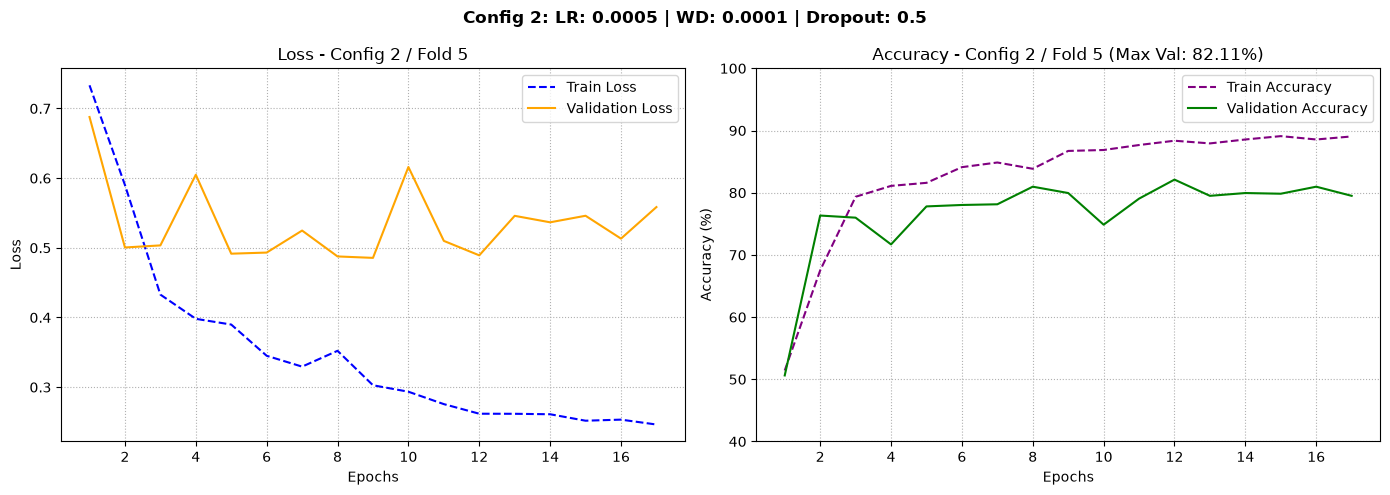

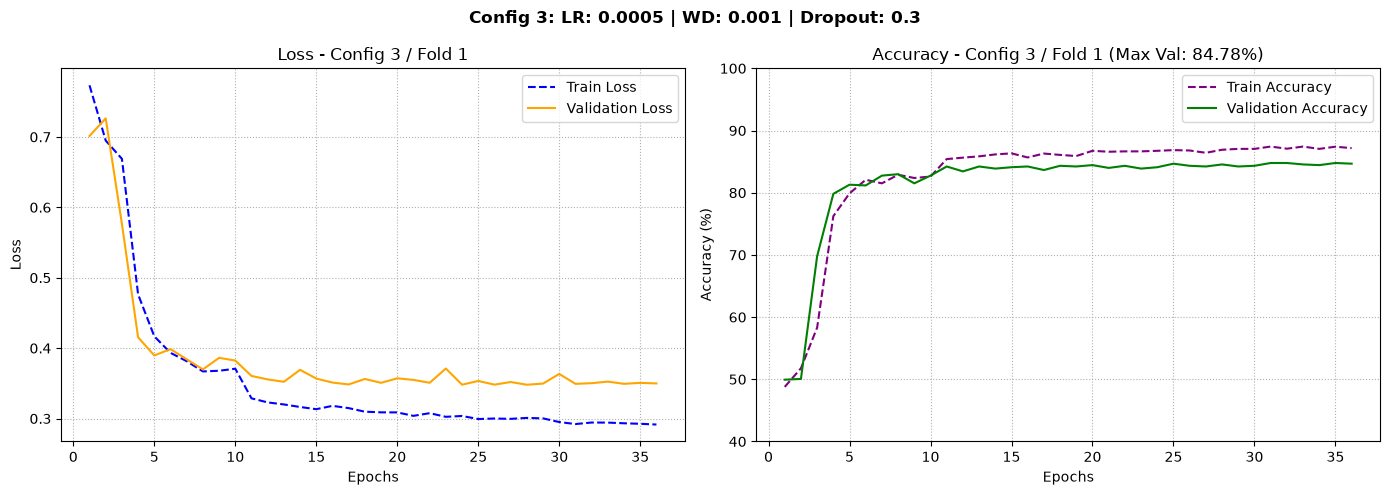

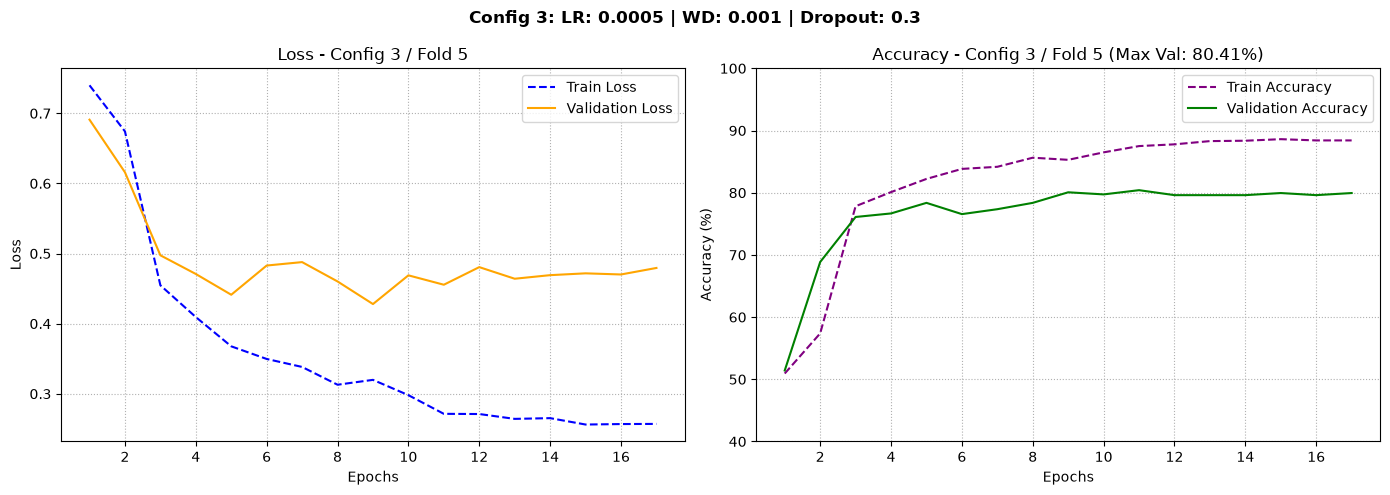

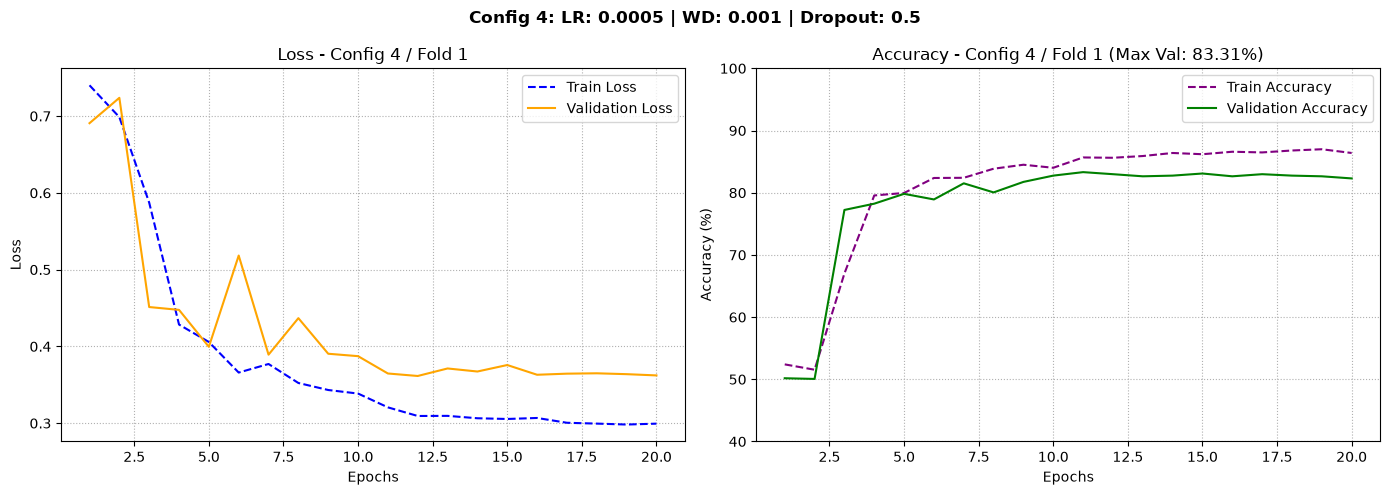

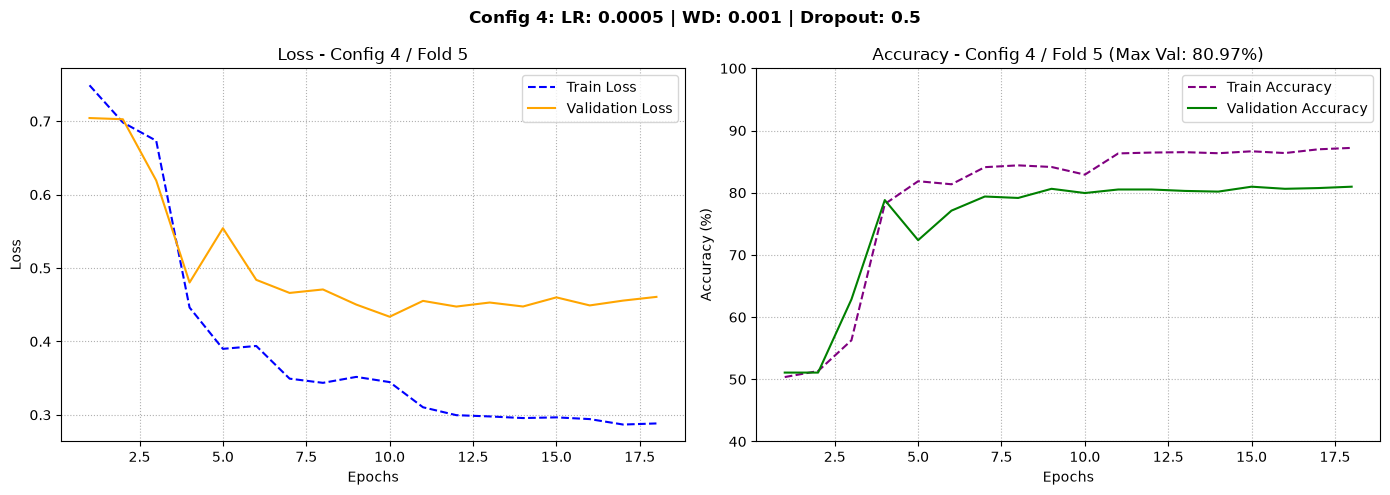

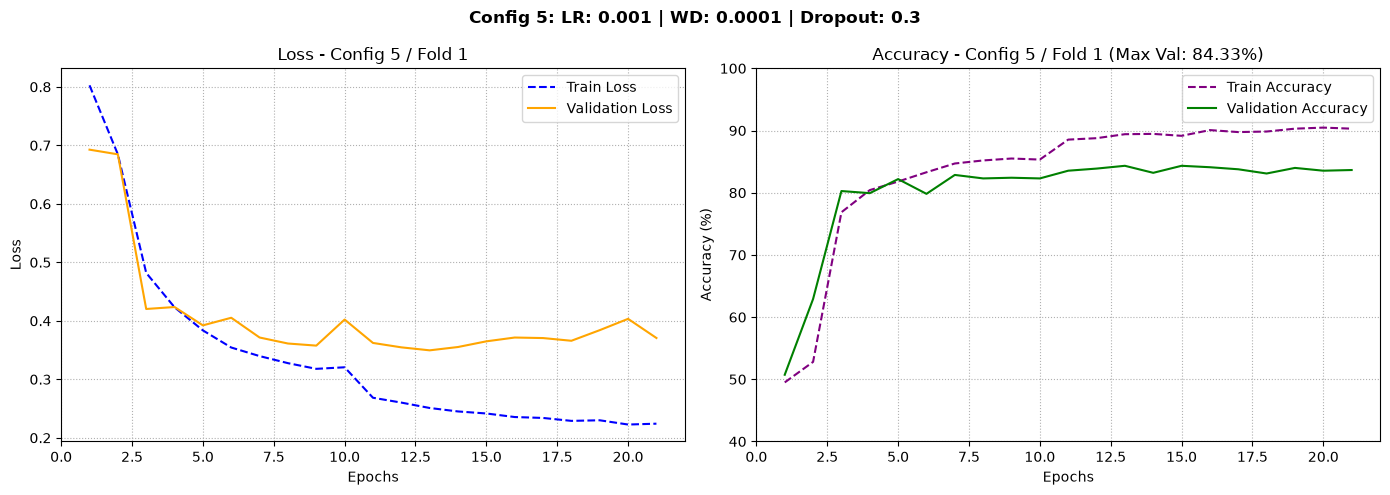

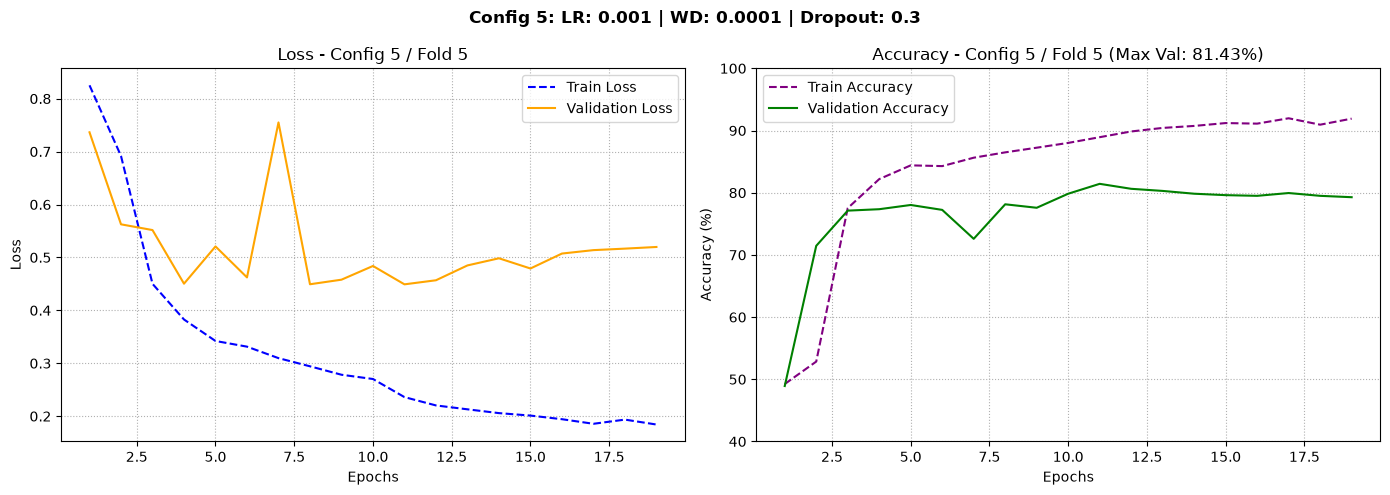

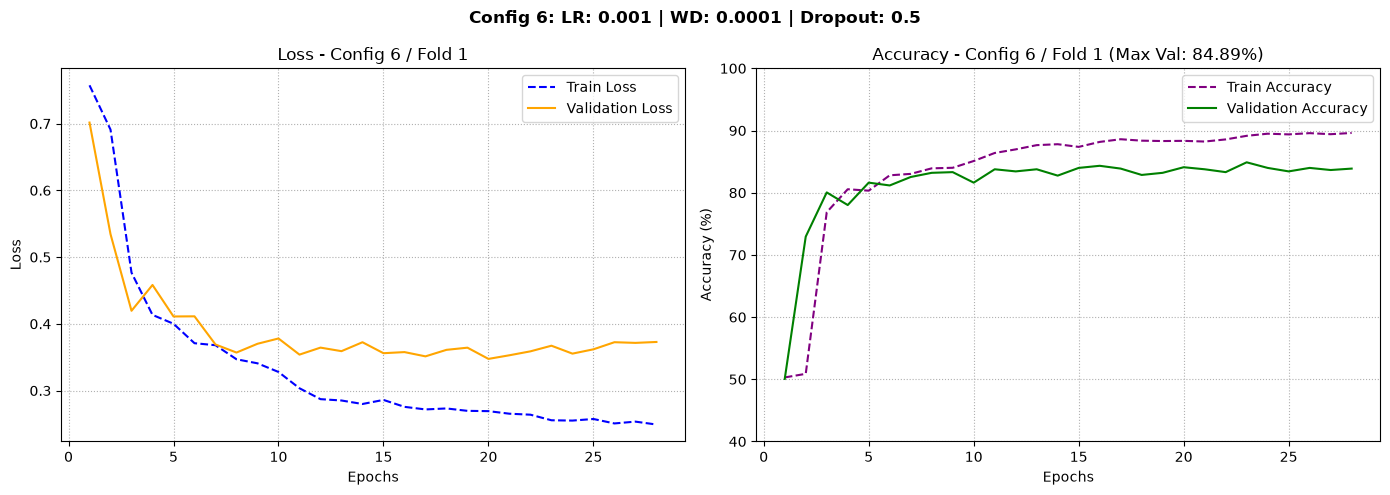

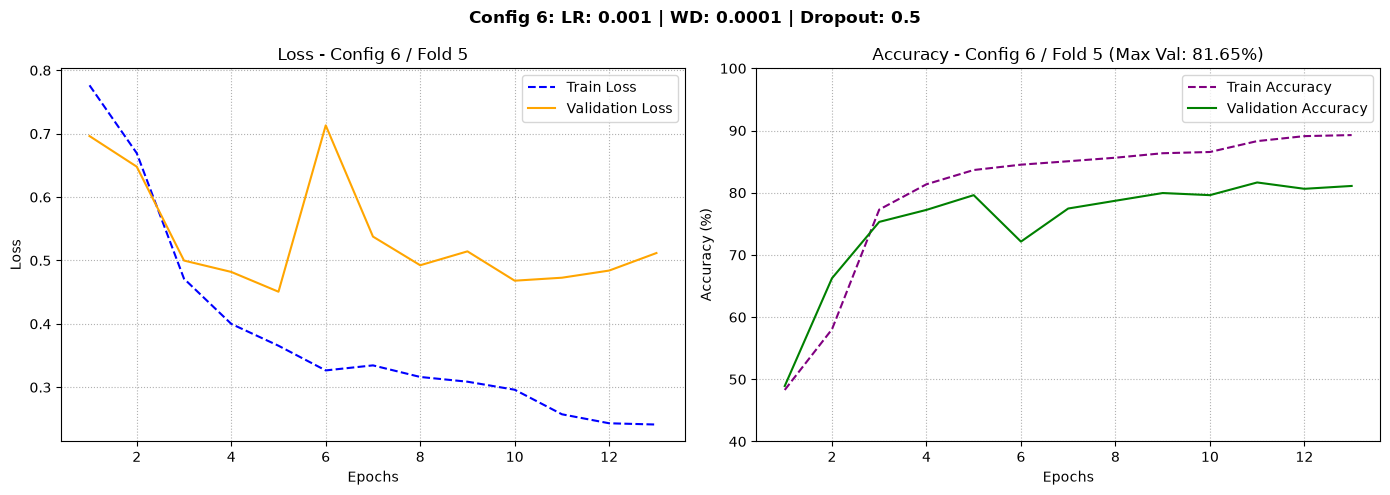

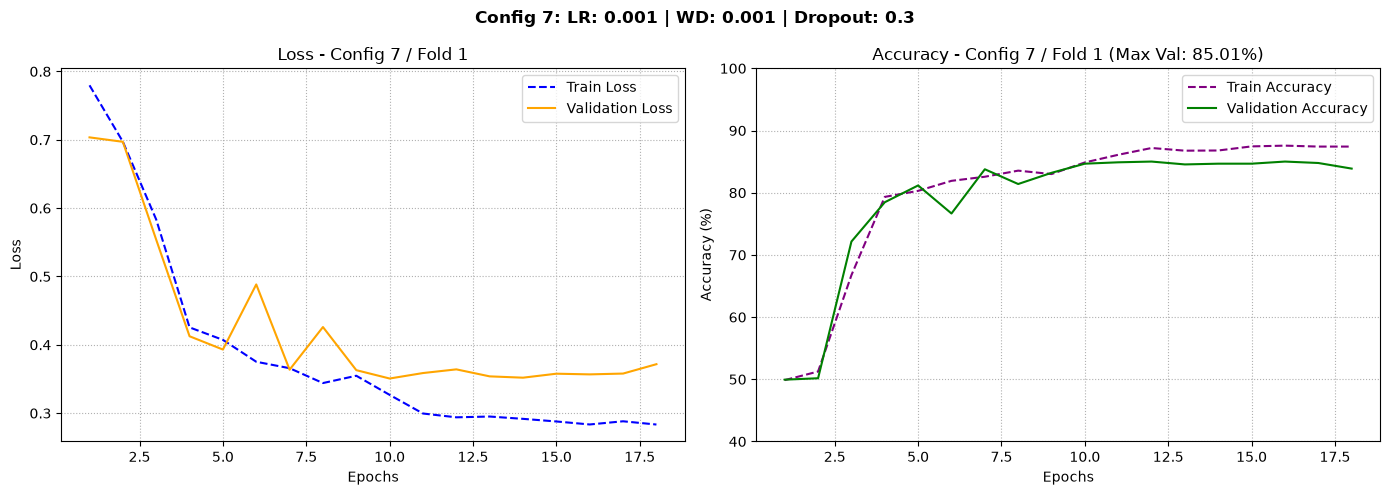

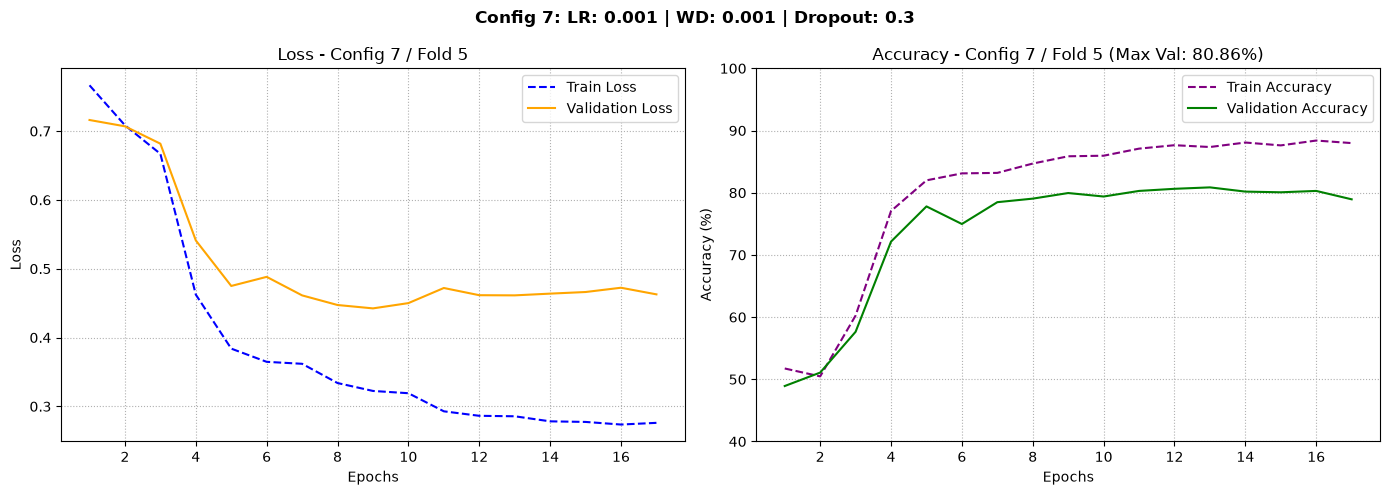

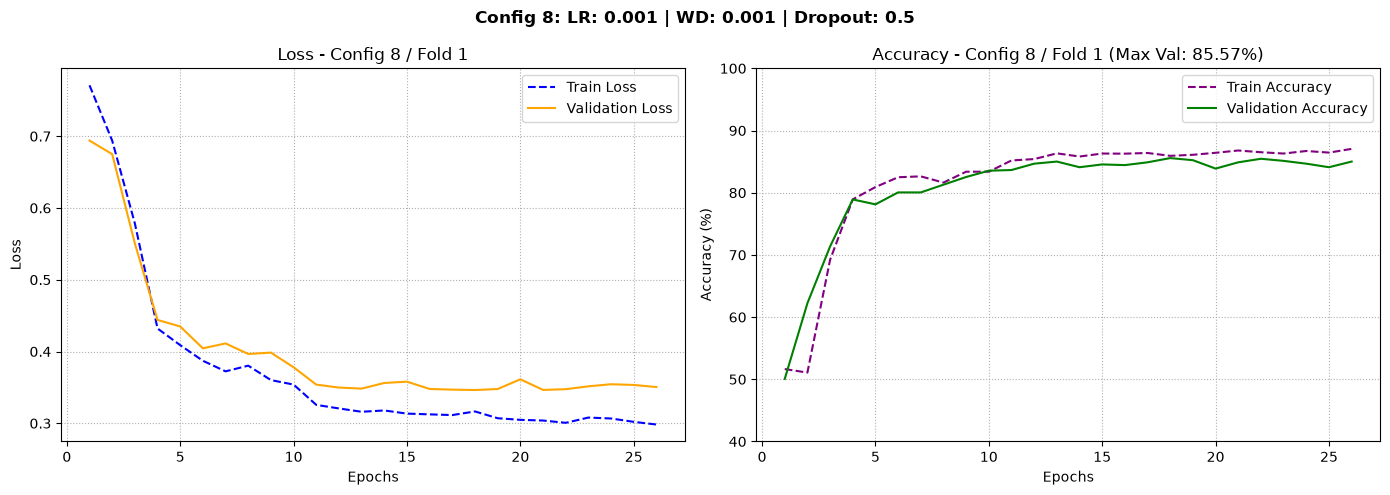

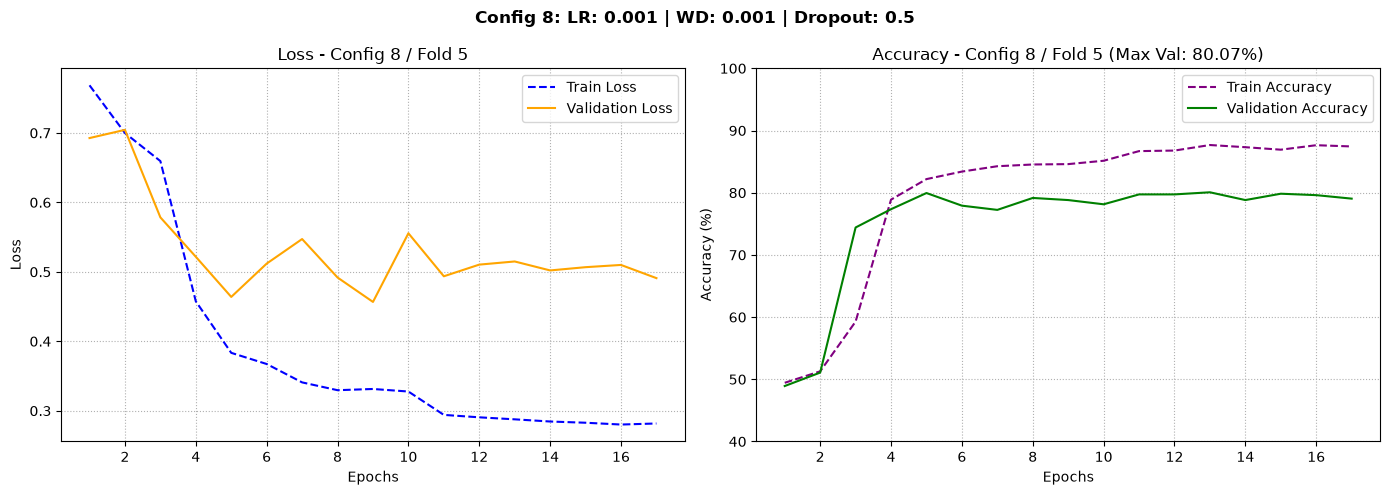

In [21]:
import re
import matplotlib.pyplot as plt

# 1. Inserisci tutti i log delle 8 configurazioni
raw_logs = """
TESTING CONFIG 1/8
LR: 0.0005 | WD: 0.0001 | Dropout: 0.3
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.73734, train_acc=50.82%, val_loss=0.68704, val_acc=53.21% | LR: 0.000500
Epoch 02/50: train_loss=0.58132, train_acc=65.63%, val_loss=0.47371, val_acc=76.10% | LR: 0.000500
Epoch 03/50: train_loss=0.41476, train_acc=79.67%, val_loss=0.39614, val_acc=81.17% | LR: 0.000500
Epoch 04/50: train_loss=0.37920, train_acc=81.17%, val_loss=0.40845, val_acc=81.51% | LR: 0.000500
Epoch 05/50: train_loss=0.36171, train_acc=83.03%, val_loss=0.35421, val_acc=83.65% | LR: 0.000500
Epoch 06/50: train_loss=0.35194, train_acc=83.09%, val_loss=0.35888, val_acc=83.43% | LR: 0.000500
Epoch 07/50: train_loss=0.33556, train_acc=84.44%, val_loss=0.36859, val_acc=82.41% | LR: 0.000500
Epoch 08/50: train_loss=0.33046, train_acc=83.95%, val_loss=0.34972, val_acc=83.88% | LR: 0.000500
Epoch 09/50: train_loss=0.31243, train_acc=85.53%, val_loss=0.32288, val_acc=84.67% | LR: 0.000500
Epoch 10/50: train_loss=0.30739, train_acc=85.44%, val_loss=0.33735, val_acc=85.12% | LR: 0.000050
Epoch 11/50: train_loss=0.27133, train_acc=87.77%, val_loss=0.33944, val_acc=84.78% | LR: 0.000050
Epoch 12/50: train_loss=0.26445, train_acc=88.26%, val_loss=0.33759, val_acc=85.01% | LR: 0.000050
Epoch 13/50: train_loss=0.25716, train_acc=88.95%, val_loss=0.34053, val_acc=85.23% | LR: 0.000050
Epoch 14/50: train_loss=0.25265, train_acc=88.80%, val_loss=0.33905, val_acc=84.89% | LR: 0.000050
Epoch 15/50: train_loss=0.25617, train_acc=88.89%, val_loss=0.34418, val_acc=85.12% | LR: 0.000050
Epoch 16/50: train_loss=0.25056, train_acc=89.00%, val_loss=0.33971, val_acc=85.12% | LR: 0.000050
Epoch 17/50: train_loss=0.24723, train_acc=88.83%, val_loss=0.34020, val_acc=85.23% | LR: 0.000050
Early stopping all'epoca 17 Fold 1 completed | Best Val Acc: 85.23%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.73723, train_acc=49.58%, val_loss=0.68664, val_acc=50.40% | LR: 0.000500
Epoch 02/50: train_loss=0.60235, train_acc=65.24%, val_loss=0.50342, val_acc=73.50% | LR: 0.000500
Epoch 03/50: train_loss=0.40276, train_acc=80.47%, val_loss=0.47572, val_acc=77.69% | LR: 0.000500
Epoch 04/50: train_loss=0.35706, train_acc=83.19%, val_loss=0.54290, val_acc=75.54% | LR: 0.000500
Epoch 05/50: train_loss=0.34214, train_acc=83.91%, val_loss=0.57624, val_acc=74.07% | LR: 0.000500
Epoch 06/50: train_loss=0.31737, train_acc=86.01%, val_loss=0.59949, val_acc=74.97% | LR: 0.000500
Epoch 07/50: train_loss=0.30388, train_acc=86.72%, val_loss=0.50281, val_acc=77.46% | LR: 0.000500
Epoch 08/50: train_loss=0.29279, train_acc=87.18%, val_loss=0.45151, val_acc=79.16% | LR: 0.000500
Epoch 09/50: train_loss=0.26992, train_acc=88.13%, val_loss=0.45296, val_acc=80.41% | LR: 0.000500
Epoch 10/50: train_loss=0.29386, train_acc=86.32%, val_loss=0.45482, val_acc=79.28% | LR: 0.000050
Epoch 11/50: train_loss=0.24222, train_acc=89.65%, val_loss=0.47776, val_acc=80.41% | LR: 0.000050
Epoch 12/50: train_loss=0.22689, train_acc=89.70%, val_loss=0.48164, val_acc=79.73% | LR: 0.000050
Epoch 13/50: train_loss=0.22636, train_acc=89.70%, val_loss=0.47996, val_acc=80.07% | LR: 0.000050
Epoch 14/50: train_loss=0.22003, train_acc=90.05%, val_loss=0.48487, val_acc=79.95% | LR: 0.000050
Epoch 15/50: train_loss=0.21769, train_acc=90.19%, val_loss=0.49557, val_acc=80.07% | LR: 0.000050
Epoch 16/50: train_loss=0.21325, train_acc=90.31%, val_loss=0.49011, val_acc=80.29% | LR: 0.000050
Early stopping all'epoca 16 Fold 5 completed | Best Val Acc: 80.41%

TESTING CONFIG 2/8
LR: 0.0005 | WD: 0.0001 | Dropout: 0.5
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.74635, train_acc=50.82%, val_loss=0.69000, val_acc=50.28% | LR: 0.000500
Epoch 02/50: train_loss=0.66134, train_acc=58.23%, val_loss=0.52447, val_acc=72.72% | LR: 0.000500
Epoch 03/50: train_loss=0.47477, train_acc=76.20%, val_loss=0.42424, val_acc=80.50% | LR: 0.000500
Epoch 04/50: train_loss=0.41149, train_acc=80.02%, val_loss=0.44340, val_acc=78.58% | LR: 0.000500
Epoch 05/50: train_loss=0.40348, train_acc=80.91%, val_loss=0.48071, val_acc=78.13% | LR: 0.000500
Epoch 06/50: train_loss=0.38064, train_acc=82.26%, val_loss=0.41461, val_acc=80.61% | LR: 0.000500
Epoch 07/50: train_loss=0.37602, train_acc=82.37%, val_loss=0.39416, val_acc=81.85% | LR: 0.000500
Epoch 08/50: train_loss=0.35472, train_acc=83.06%, val_loss=0.37310, val_acc=82.19% | LR: 0.000500
Epoch 09/50: train_loss=0.34897, train_acc=83.46%, val_loss=0.37407, val_acc=82.98% | LR: 0.000500
Epoch 10/50: train_loss=0.32367, train_acc=86.16%, val_loss=0.37376, val_acc=83.20% | LR: 0.000050
Epoch 11/50: train_loss=0.29631, train_acc=86.62%, val_loss=0.37104, val_acc=82.30% | LR: 0.000050
Epoch 12/50: train_loss=0.29410, train_acc=87.17%, val_loss=0.37052, val_acc=82.86% | LR: 0.000050
Epoch 13/50: train_loss=0.28848, train_acc=87.11%, val_loss=0.37494, val_acc=83.43% | LR: 0.000050
Epoch 14/50: train_loss=0.28586, train_acc=87.54%, val_loss=0.37132, val_acc=82.98% | LR: 0.000050
Epoch 15/50: train_loss=0.28684, train_acc=87.28%, val_loss=0.37366, val_acc=82.64% | LR: 0.000050
Epoch 16/50: train_loss=0.28691, train_acc=87.34%, val_loss=0.37036, val_acc=82.86% | LR: 0.000050
Epoch 17/50: train_loss=0.28401, train_acc=87.45%, val_loss=0.38113, val_acc=83.20% | LR: 0.000050
Epoch 18/50: train_loss=0.28474, train_acc=87.34%, val_loss=0.36732, val_acc=83.65% | LR: 0.000050
Epoch 19/50: train_loss=0.28037, train_acc=88.14%, val_loss=0.37218, val_acc=83.65% | LR: 0.000050
Epoch 20/50: train_loss=0.27946, train_acc=87.54%, val_loss=0.37103, val_acc=83.43% | LR: 0.000050
Epoch 21/50: train_loss=0.27573, train_acc=87.65%, val_loss=0.37128, val_acc=83.20% | LR: 0.000050
Epoch 22/50: train_loss=0.27795, train_acc=87.83%, val_loss=0.37360, val_acc=83.54% | LR: 0.000050
Epoch 23/50: train_loss=0.27140, train_acc=88.00%, val_loss=0.37084, val_acc=83.65% | LR: 0.000050
Epoch 24/50: train_loss=0.27126, train_acc=88.03%, val_loss=0.37935, val_acc=83.54% | LR: 0.000050
Epoch 25/50: train_loss=0.27140, train_acc=88.00%, val_loss=0.37504, val_acc=83.20% | LR: 0.000050
Epoch 26/50: train_loss=0.26486, train_acc=88.95%, val_loss=0.37793, val_acc=83.65% | LR: 0.000050
Early stopping all'epoca 26 Fold 1 completed | Best Val Acc: 83.65%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.73330, train_acc=51.42%, val_loss=0.68780, val_acc=50.62% | LR: 0.000500
Epoch 02/50: train_loss=0.59011, train_acc=67.51%, val_loss=0.50051, val_acc=76.33% | LR: 0.000500
Epoch 03/50: train_loss=0.43287, train_acc=79.35%, val_loss=0.50348, val_acc=75.99% | LR: 0.000500
Epoch 04/50: train_loss=0.39809, train_acc=81.10%, val_loss=0.60489, val_acc=71.69% | LR: 0.000500
Epoch 05/50: train_loss=0.38986, train_acc=81.59%, val_loss=0.49160, val_acc=77.80% | LR: 0.000500
Epoch 06/50: train_loss=0.34506, train_acc=84.11%, val_loss=0.49319, val_acc=78.03% | LR: 0.000500
Epoch 07/50: train_loss=0.32947, train_acc=84.86%, val_loss=0.52479, val_acc=78.14% | LR: 0.000500
Epoch 08/50: train_loss=0.35219, train_acc=83.85%, val_loss=0.48764, val_acc=80.97% | LR: 0.000500
Epoch 09/50: train_loss=0.30273, train_acc=86.72%, val_loss=0.48558, val_acc=79.95% | LR: 0.000500
Epoch 10/50: train_loss=0.29346, train_acc=86.87%, val_loss=0.61603, val_acc=74.86% | LR: 0.000050
Epoch 11/50: train_loss=0.27566, train_acc=87.67%, val_loss=0.50997, val_acc=79.05% | LR: 0.000050
Epoch 12/50: train_loss=0.26187, train_acc=88.36%, val_loss=0.48920, val_acc=82.11% | LR: 0.000050
Epoch 13/50: train_loss=0.26177, train_acc=87.93%, val_loss=0.54593, val_acc=79.50% | LR: 0.000050
Epoch 14/50: train_loss=0.26111, train_acc=88.56%, val_loss=0.53663, val_acc=79.95% | LR: 0.000050
Epoch 15/50: train_loss=0.25184, train_acc=89.10%, val_loss=0.54604, val_acc=79.84% | LR: 0.000050
Epoch 16/50: train_loss=0.25339, train_acc=88.56%, val_loss=0.51321, val_acc=80.97% | LR: 0.000050
Epoch 17/50: train_loss=0.24635, train_acc=89.05%, val_loss=0.55851, val_acc=79.50% | LR: 0.000050
Early stopping all'epoca 17 Fold 5 completed | Best Val Acc: 82.11%

TESTING CONFIG 3/8
LR: 0.0005 | WD: 0.001 | Dropout: 0.3
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.77332, train_acc=48.78%, val_loss=0.70134, val_acc=49.94% | LR: 0.000500
Epoch 02/50: train_loss=0.69482, train_acc=51.77%, val_loss=0.72641, val_acc=50.06% | LR: 0.000500
Epoch 03/50: train_loss=0.66889, train_acc=58.31%, val_loss=0.57658, val_acc=69.79% | LR: 0.000500
Epoch 04/50: train_loss=0.47624, train_acc=76.23%, val_loss=0.41532, val_acc=79.82% | LR: 0.000500
Epoch 05/50: train_loss=0.41680, train_acc=79.90%, val_loss=0.38962, val_acc=81.29% | LR: 0.000500
Epoch 06/50: train_loss=0.39336, train_acc=82.08%, val_loss=0.39866, val_acc=81.17% | LR: 0.000500
Epoch 07/50: train_loss=0.38146, train_acc=81.51%, val_loss=0.38417, val_acc=82.75% | LR: 0.000500
Epoch 08/50: train_loss=0.36694, train_acc=82.89%, val_loss=0.36984, val_acc=82.98% | LR: 0.000500
Epoch 09/50: train_loss=0.36790, train_acc=82.37%, val_loss=0.38624, val_acc=81.51% | LR: 0.000500
Epoch 10/50: train_loss=0.37078, train_acc=82.60%, val_loss=0.38240, val_acc=82.75% | LR: 0.000050
Epoch 11/50: train_loss=0.32870, train_acc=85.41%, val_loss=0.36056, val_acc=84.22% | LR: 0.000050
Epoch 12/50: train_loss=0.32296, train_acc=85.64%, val_loss=0.35558, val_acc=83.43% | LR: 0.000050
Epoch 13/50: train_loss=0.32006, train_acc=85.85%, val_loss=0.35222, val_acc=84.22% | LR: 0.000050
Epoch 14/50: train_loss=0.31644, train_acc=86.16%, val_loss=0.36925, val_acc=83.88% | LR: 0.000050
Epoch 15/50: train_loss=0.31332, train_acc=86.33%, val_loss=0.35677, val_acc=84.10% | LR: 0.000050
Epoch 16/50: train_loss=0.31805, train_acc=85.67%, val_loss=0.35113, val_acc=84.22% | LR: 0.000050
Epoch 17/50: train_loss=0.31483, train_acc=86.30%, val_loss=0.34846, val_acc=83.65% | LR: 0.000050
Epoch 18/50: train_loss=0.30976, train_acc=86.08%, val_loss=0.35623, val_acc=84.33% | LR: 0.000050
Epoch 19/50: train_loss=0.30884, train_acc=85.90%, val_loss=0.35077, val_acc=84.22% | LR: 0.000050
Epoch 20/50: train_loss=0.30874, train_acc=86.74%, val_loss=0.35715, val_acc=84.44% | LR: 0.000050
Epoch 21/50: train_loss=0.30385, train_acc=86.59%, val_loss=0.35492, val_acc=83.99% | LR: 0.000050
Epoch 22/50: train_loss=0.30766, train_acc=86.65%, val_loss=0.35079, val_acc=84.33% | LR: 0.000050
Epoch 23/50: train_loss=0.30248, train_acc=86.65%, val_loss=0.37106, val_acc=83.88% | LR: 0.000050
Epoch 24/50: train_loss=0.30366, train_acc=86.74%, val_loss=0.34811, val_acc=84.10% | LR: 0.000050
Epoch 25/50: train_loss=0.29934, train_acc=86.85%, val_loss=0.35342, val_acc=84.67% | LR: 0.000050
Epoch 26/50: train_loss=0.30007, train_acc=86.79%, val_loss=0.34816, val_acc=84.33% | LR: 0.000050
Epoch 27/50: train_loss=0.29960, train_acc=86.42%, val_loss=0.35192, val_acc=84.22% | LR: 0.000050
Epoch 28/50: train_loss=0.30092, train_acc=86.91%, val_loss=0.34805, val_acc=84.55% | LR: 0.000050
Epoch 29/50: train_loss=0.30026, train_acc=87.05%, val_loss=0.34968, val_acc=84.22% | LR: 0.000050
Epoch 30/50: train_loss=0.29504, train_acc=87.05%, val_loss=0.36340, val_acc=84.33% | LR: 0.000005
Epoch 31/50: train_loss=0.29220, train_acc=87.42%, val_loss=0.34929, val_acc=84.78% | LR: 0.000005
Epoch 32/50: train_loss=0.29437, train_acc=87.08%, val_loss=0.35026, val_acc=84.78% | LR: 0.000005
Epoch 33/50: train_loss=0.29426, train_acc=87.42%, val_loss=0.35248, val_acc=84.55% | LR: 0.000005
Epoch 34/50: train_loss=0.29332, train_acc=87.05%, val_loss=0.34934, val_acc=84.44% | LR: 0.000005
Epoch 35/50: train_loss=0.29257, train_acc=87.40%, val_loss=0.35068, val_acc=84.78% | LR: 0.000005
Epoch 36/50: train_loss=0.29152, train_acc=87.17%, val_loss=0.34991, val_acc=84.67% | LR: 0.000005
Early stopping all'epoca 36 Fold 1 completed | Best Val Acc: 84.78%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.73995, train_acc=50.93%, val_loss=0.69092, val_acc=51.42% | LR: 0.000500
Epoch 02/50: train_loss=0.67421, train_acc=57.38%, val_loss=0.61589, val_acc=68.86% | LR: 0.000500
Epoch 03/50: train_loss=0.45468, train_acc=77.83%, val_loss=0.49747, val_acc=76.10% | LR: 0.000500
Epoch 04/50: train_loss=0.40941, train_acc=80.10%, val_loss=0.47085, val_acc=76.67% | LR: 0.000500
Epoch 05/50: train_loss=0.36766, train_acc=82.22%, val_loss=0.44123, val_acc=78.37% | LR: 0.000500
Epoch 06/50: train_loss=0.34964, train_acc=83.83%, val_loss=0.48289, val_acc=76.56% | LR: 0.000500
Epoch 07/50: train_loss=0.33825, train_acc=84.17%, val_loss=0.48778, val_acc=77.35% | LR: 0.000500
Epoch 08/50: train_loss=0.31289, train_acc=85.63%, val_loss=0.46020, val_acc=78.37% | LR: 0.000500
Epoch 09/50: train_loss=0.31984, train_acc=85.29%, val_loss=0.42794, val_acc=80.07% | LR: 0.000500
Epoch 10/50: train_loss=0.29801, train_acc=86.49%, val_loss=0.46891, val_acc=79.73% | LR: 0.000050
Epoch 11/50: train_loss=0.27138, train_acc=87.50%, val_loss=0.45551, val_acc=80.41% | LR: 0.000050
Epoch 12/50: train_loss=0.27111, train_acc=87.78%, val_loss=0.48062, val_acc=79.61% | LR: 0.000050
Epoch 13/50: train_loss=0.26419, train_acc=88.30%, val_loss=0.46406, val_acc=79.61% | LR: 0.000050
Epoch 14/50: train_loss=0.26524, train_acc=88.36%, val_loss=0.46917, val_acc=79.61% | LR: 0.000050
Epoch 15/50: train_loss=0.25612, train_acc=88.61%, val_loss=0.47176, val_acc=79.95% | LR: 0.000050
Epoch 16/50: train_loss=0.25681, train_acc=88.41%, val_loss=0.47014, val_acc=79.61% | LR: 0.000050
Epoch 17/50: train_loss=0.25701, train_acc=88.41%, val_loss=0.47944, val_acc=79.95% | LR: 0.000050
Early stopping all'epoca 17 Fold 5 completed | Best Val Acc: 80.41%

TESTING CONFIG 4/8
LR: 0.0005 | WD: 0.001 | Dropout: 0.5
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.74009, train_acc=52.40%, val_loss=0.69075, val_acc=50.17% | LR: 0.000500
Epoch 02/50: train_loss=0.69865, train_acc=51.54%, val_loss=0.72377, val_acc=50.06% | LR: 0.000500
Epoch 03/50: train_loss=0.58727, train_acc=67.01%, val_loss=0.45129, val_acc=77.23% | LR: 0.000500
Epoch 04/50: train_loss=0.42848, train_acc=79.56%, val_loss=0.44760, val_acc=78.24% | LR: 0.000500
Epoch 05/50: train_loss=0.40577, train_acc=79.96%, val_loss=0.39948, val_acc=79.82% | LR: 0.000500
Epoch 06/50: train_loss=0.36595, train_acc=82.37%, val_loss=0.51835, val_acc=78.92% | LR: 0.000500
Epoch 07/50: train_loss=0.37711, train_acc=82.40%, val_loss=0.38926, val_acc=81.51% | LR: 0.000500
Epoch 08/50: train_loss=0.35238, train_acc=83.86%, val_loss=0.43682, val_acc=80.05% | LR: 0.000500
Epoch 09/50: train_loss=0.34323, train_acc=84.50%, val_loss=0.39046, val_acc=81.74% | LR: 0.000500
Epoch 10/50: train_loss=0.33861, train_acc=84.01%, val_loss=0.38732, val_acc=82.75% | LR: 0.000050
Epoch 11/50: train_loss=0.32064, train_acc=85.67%, val_loss=0.36474, val_acc=83.31% | LR: 0.000050
Epoch 12/50: train_loss=0.30940, train_acc=85.62%, val_loss=0.36150, val_acc=82.98% | LR: 0.000050
Epoch 13/50: train_loss=0.30955, train_acc=85.90%, val_loss=0.37128, val_acc=82.64% | LR: 0.000050
Epoch 14/50: train_loss=0.30644, train_acc=86.39%, val_loss=0.36732, val_acc=82.75% | LR: 0.000050
Epoch 15/50: train_loss=0.30550, train_acc=86.19%, val_loss=0.37577, val_acc=83.09% | LR: 0.000050
Epoch 16/50: train_loss=0.30681, train_acc=86.59%, val_loss=0.36309, val_acc=82.64% | LR: 0.000050
Epoch 17/50: train_loss=0.30056, train_acc=86.48%, val_loss=0.36452, val_acc=82.98% | LR: 0.000050
Epoch 18/50: train_loss=0.29947, train_acc=86.79%, val_loss=0.36499, val_acc=82.75% | LR: 0.000050
Epoch 19/50: train_loss=0.29826, train_acc=86.99%, val_loss=0.36386, val_acc=82.64% | LR: 0.000050
Epoch 20/50: train_loss=0.29940, train_acc=86.39%, val_loss=0.36224, val_acc=82.30% | LR: 0.000050
Early stopping all'epoca 20 Fold 1 completed | Best Val Acc: 83.31%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.74892, train_acc=50.36%, val_loss=0.70432, val_acc=51.08% | LR: 0.000500
Epoch 02/50: train_loss=0.69834, train_acc=51.33%, val_loss=0.70269, val_acc=51.08% | LR: 0.000500
Epoch 03/50: train_loss=0.67341, train_acc=56.27%, val_loss=0.61927, val_acc=62.85% | LR: 0.000500
Epoch 04/50: train_loss=0.44622, train_acc=78.18%, val_loss=0.48026, val_acc=78.82% | LR: 0.000500
Epoch 05/50: train_loss=0.38988, train_acc=81.85%, val_loss=0.55424, val_acc=72.37% | LR: 0.000500
Epoch 06/50: train_loss=0.39382, train_acc=81.36%, val_loss=0.48390, val_acc=77.12% | LR: 0.000500
Epoch 07/50: train_loss=0.34929, train_acc=84.11%, val_loss=0.46607, val_acc=79.39% | LR: 0.000500
Epoch 08/50: train_loss=0.34359, train_acc=84.40%, val_loss=0.47080, val_acc=79.16% | LR: 0.000500
Epoch 09/50: train_loss=0.35169, train_acc=84.14%, val_loss=0.45019, val_acc=80.63% | LR: 0.000500
Epoch 10/50: train_loss=0.34460, train_acc=82.91%, val_loss=0.43365, val_acc=79.95% | LR: 0.000050
Epoch 11/50: train_loss=0.31031, train_acc=86.32%, val_loss=0.45524, val_acc=80.52% | LR: 0.000050
Epoch 12/50: train_loss=0.29954, train_acc=86.46%, val_loss=0.44751, val_acc=80.52% | LR: 0.000050
Epoch 13/50: train_loss=0.29782, train_acc=86.52%, val_loss=0.45300, val_acc=80.29% | LR: 0.000050
Epoch 14/50: train_loss=0.29562, train_acc=86.35%, val_loss=0.44760, val_acc=80.18% | LR: 0.000050
Epoch 15/50: train_loss=0.29655, train_acc=86.66%, val_loss=0.46001, val_acc=80.97% | LR: 0.000050
Epoch 16/50: train_loss=0.29420, train_acc=86.38%, val_loss=0.44906, val_acc=80.63% | LR: 0.000050
Epoch 17/50: train_loss=0.28679, train_acc=86.98%, val_loss=0.45562, val_acc=80.75% | LR: 0.000050
Epoch 18/50: train_loss=0.28827, train_acc=87.21%, val_loss=0.46069, val_acc=80.97% | LR: 0.000050
Early stopping all'epoca 18 Fold 5 completed | Best Val Acc: 80.97%

TESTING CONFIG 5/8
LR: 0.001 | WD: 0.0001 | Dropout: 0.3
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.80265, train_acc=49.50%, val_loss=0.69263, val_acc=50.73% | LR: 0.001000
Epoch 02/50: train_loss=0.68464, train_acc=52.80%, val_loss=0.68464, val_acc=62.91% | LR: 0.001000
Epoch 03/50: train_loss=0.48195, train_acc=76.86%, val_loss=0.42026, val_acc=80.27% | LR: 0.001000
Epoch 04/50: train_loss=0.42314, train_acc=80.42%, val_loss=0.42360, val_acc=79.93% | LR: 0.001000
Epoch 05/50: train_loss=0.38365, train_acc=81.80%, val_loss=0.39225, val_acc=82.19% | LR: 0.001000
Epoch 06/50: train_loss=0.35438, train_acc=83.29%, val_loss=0.40527, val_acc=79.82% | LR: 0.001000
Epoch 07/50: train_loss=0.33973, train_acc=84.70%, val_loss=0.37149, val_acc=82.86% | LR: 0.001000
Epoch 08/50: train_loss=0.32765, train_acc=85.19%, val_loss=0.36123, val_acc=82.30% | LR: 0.001000
Epoch 09/50: train_loss=0.31793, train_acc=85.50%, val_loss=0.35763, val_acc=82.41% | LR: 0.001000
Epoch 10/50: train_loss=0.32059, train_acc=85.33%, val_loss=0.40218, val_acc=82.30% | LR: 0.000100
Epoch 11/50: train_loss=0.26850, train_acc=88.54%, val_loss=0.36221, val_acc=83.54% | LR: 0.000100
Epoch 12/50: train_loss=0.26024, train_acc=88.77%, val_loss=0.35468, val_acc=83.88% | LR: 0.000100
Epoch 13/50: train_loss=0.25101, train_acc=89.41%, val_loss=0.34956, val_acc=84.33% | LR: 0.000100
Epoch 14/50: train_loss=0.24510, train_acc=89.46%, val_loss=0.35525, val_acc=83.20% | LR: 0.000100
Epoch 15/50: train_loss=0.24162, train_acc=89.15%, val_loss=0.36495, val_acc=84.33% | LR: 0.000100
Epoch 16/50: train_loss=0.23554, train_acc=90.07%, val_loss=0.37145, val_acc=84.10% | LR: 0.000100
Epoch 17/50: train_loss=0.23399, train_acc=89.75%, val_loss=0.37055, val_acc=83.77% | LR: 0.000100
Epoch 18/50: train_loss=0.22898, train_acc=89.84%, val_loss=0.36592, val_acc=83.09% | LR: 0.000100
Epoch 19/50: train_loss=0.22999, train_acc=90.30%, val_loss=0.38407, val_acc=83.99% | LR: 0.000100
Epoch 20/50: train_loss=0.22272, train_acc=90.47%, val_loss=0.40340, val_acc=83.54% | LR: 0.000100
Epoch 21/50: train_loss=0.22418, train_acc=90.30%, val_loss=0.37067, val_acc=83.65% | LR: 0.000100
Early stopping all'epoca 21 Fold 1 completed | Best Val Acc: 84.33%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.82525, train_acc=49.24%, val_loss=0.73644, val_acc=48.92% | LR: 0.001000
Epoch 02/50: train_loss=0.69163, train_acc=52.85%, val_loss=0.56255, val_acc=71.46% | LR: 0.001000
Epoch 03/50: train_loss=0.45012, train_acc=77.52%, val_loss=0.55170, val_acc=77.12% | LR: 0.001000
Epoch 04/50: train_loss=0.38271, train_acc=82.19%, val_loss=0.45039, val_acc=77.35% | LR: 0.001000
Epoch 05/50: train_loss=0.34211, train_acc=84.40%, val_loss=0.52077, val_acc=78.03% | LR: 0.001000
Epoch 06/50: train_loss=0.33140, train_acc=84.28%, val_loss=0.46225, val_acc=77.24% | LR: 0.001000
Epoch 07/50: train_loss=0.30970, train_acc=85.63%, val_loss=0.75510, val_acc=72.59% | LR: 0.001000
Epoch 08/50: train_loss=0.29425, train_acc=86.49%, val_loss=0.44930, val_acc=78.14% | LR: 0.001000
Epoch 09/50: train_loss=0.27832, train_acc=87.24%, val_loss=0.45794, val_acc=77.58% | LR: 0.001000
Epoch 10/50: train_loss=0.27025, train_acc=88.01%, val_loss=0.48383, val_acc=79.84% | LR: 0.000100
Epoch 11/50: train_loss=0.23605, train_acc=88.93%, val_loss=0.44914, val_acc=81.43% | LR: 0.000100
Epoch 12/50: train_loss=0.22033, train_acc=89.85%, val_loss=0.45684, val_acc=80.63% | LR: 0.000100
Epoch 13/50: train_loss=0.21298, train_acc=90.42%, val_loss=0.48488, val_acc=80.29% | LR: 0.000100
Epoch 14/50: train_loss=0.20580, train_acc=90.74%, val_loss=0.49839, val_acc=79.84% | LR: 0.000100
Epoch 15/50: train_loss=0.20116, train_acc=91.20%, val_loss=0.47908, val_acc=79.61% | LR: 0.000100
Epoch 16/50: train_loss=0.19431, train_acc=91.11%, val_loss=0.50732, val_acc=79.50% | LR: 0.000100
Epoch 17/50: train_loss=0.18565, train_acc=91.97%, val_loss=0.51379, val_acc=79.95% | LR: 0.000100
Epoch 18/50: train_loss=0.19353, train_acc=90.94%, val_loss=0.51663, val_acc=79.50% | LR: 0.000100
Epoch 19/50: train_loss=0.18423, train_acc=91.91%, val_loss=0.51974, val_acc=79.28% | LR: 0.000100
Early stopping all'epoca 19 Fold 5 completed | Best Val Acc: 81.43%

TESTING CONFIG 6/8
LR: 0.001 | WD: 0.0001 | Dropout: 0.5
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.75741, train_acc=50.30%, val_loss=0.70158, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69106, train_acc=50.88%, val_loss=0.53443, val_acc=72.94% | LR: 0.001000
Epoch 03/50: train_loss=0.47675, train_acc=76.86%, val_loss=0.41956, val_acc=80.05% | LR: 0.001000
Epoch 04/50: train_loss=0.41338, train_acc=80.56%, val_loss=0.45824, val_acc=78.02% | LR: 0.001000
Epoch 05/50: train_loss=0.40013, train_acc=80.33%, val_loss=0.41104, val_acc=81.62% | LR: 0.001000
Epoch 06/50: train_loss=0.37097, train_acc=82.80%, val_loss=0.41125, val_acc=81.17% | LR: 0.001000
Epoch 07/50: train_loss=0.36798, train_acc=83.03%, val_loss=0.36905, val_acc=82.53% | LR: 0.001000
Epoch 08/50: train_loss=0.34691, train_acc=83.92%, val_loss=0.35699, val_acc=83.20% | LR: 0.001000
Epoch 09/50: train_loss=0.34084, train_acc=84.01%, val_loss=0.37012, val_acc=83.31% | LR: 0.001000
Epoch 10/50: train_loss=0.32790, train_acc=85.10%, val_loss=0.37806, val_acc=81.62% | LR: 0.000100
Epoch 11/50: train_loss=0.30346, train_acc=86.39%, val_loss=0.35389, val_acc=83.77% | LR: 0.000100
Epoch 12/50: train_loss=0.28715, train_acc=86.97%, val_loss=0.36437, val_acc=83.43% | LR: 0.000100
Epoch 13/50: train_loss=0.28514, train_acc=87.65%, val_loss=0.35906, val_acc=83.77% | LR: 0.000100
Epoch 14/50: train_loss=0.27990, train_acc=87.80%, val_loss=0.37244, val_acc=82.75% | LR: 0.000100
Epoch 15/50: train_loss=0.28601, train_acc=87.37%, val_loss=0.35600, val_acc=83.99% | LR: 0.000100
Epoch 16/50: train_loss=0.27562, train_acc=88.17%, val_loss=0.35766, val_acc=84.33% | LR: 0.000100
Epoch 17/50: train_loss=0.27175, train_acc=88.60%, val_loss=0.35127, val_acc=83.88% | LR: 0.000100
Epoch 18/50: train_loss=0.27323, train_acc=88.37%, val_loss=0.36103, val_acc=82.86% | LR: 0.000100
Epoch 19/50: train_loss=0.26963, train_acc=88.31%, val_loss=0.36428, val_acc=83.20% | LR: 0.000100
Epoch 20/50: train_loss=0.26919, train_acc=88.34%, val_loss=0.34747, val_acc=84.10% | LR: 0.000100
Epoch 21/50: train_loss=0.26534, train_acc=88.23%, val_loss=0.35291, val_acc=83.77% | LR: 0.000100
Epoch 22/50: train_loss=0.26387, train_acc=88.57%, val_loss=0.35880, val_acc=83.31% | LR: 0.000100
Epoch 23/50: train_loss=0.25551, train_acc=89.15%, val_loss=0.36722, val_acc=84.89% | LR: 0.000100
Epoch 24/50: train_loss=0.25504, train_acc=89.49%, val_loss=0.35536, val_acc=83.99% | LR: 0.000100
Epoch 25/50: train_loss=0.25742, train_acc=89.38%, val_loss=0.36183, val_acc=83.43% | LR: 0.000100
Epoch 26/50: train_loss=0.25076, train_acc=89.58%, val_loss=0.37247, val_acc=83.99% | LR: 0.000100
Epoch 27/50: train_loss=0.25348, train_acc=89.41%, val_loss=0.37147, val_acc=83.65% | LR: 0.000100
Epoch 28/50: train_loss=0.24912, train_acc=89.61%, val_loss=0.37283, val_acc=83.88% | LR: 0.000100
Early stopping all'epoca 28 Fold 1 completed | Best Val Acc: 84.89%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.77636, train_acc=48.29%, val_loss=0.69630, val_acc=48.92% | LR: 0.001000
Epoch 02/50: train_loss=0.66927, train_acc=58.04%, val_loss=0.64797, val_acc=66.25% | LR: 0.001000
Epoch 03/50: train_loss=0.47125, train_acc=77.29%, val_loss=0.49987, val_acc=75.31% | LR: 0.001000
Epoch 04/50: train_loss=0.39999, train_acc=81.36%, val_loss=0.48194, val_acc=77.24% | LR: 0.001000
Epoch 05/50: train_loss=0.36551, train_acc=83.65%, val_loss=0.45072, val_acc=79.61% | LR: 0.001000
Epoch 06/50: train_loss=0.32656, train_acc=84.51%, val_loss=0.71314, val_acc=72.14% | LR: 0.001000
Epoch 07/50: train_loss=0.33452, train_acc=85.06%, val_loss=0.53768, val_acc=77.46% | LR: 0.001000
Epoch 08/50: train_loss=0.31624, train_acc=85.63%, val_loss=0.49247, val_acc=78.71% | LR: 0.001000
Epoch 09/50: train_loss=0.30877, train_acc=86.35%, val_loss=0.51440, val_acc=79.95% | LR: 0.001000
Epoch 10/50: train_loss=0.29609, train_acc=86.55%, val_loss=0.46812, val_acc=79.61% | LR: 0.000100
Epoch 11/50: train_loss=0.25736, train_acc=88.30%, val_loss=0.47281, val_acc=81.65% | LR: 0.000100
Epoch 12/50: train_loss=0.24317, train_acc=89.10%, val_loss=0.48410, val_acc=80.63% | LR: 0.000100
Epoch 13/50: train_loss=0.24119, train_acc=89.27%, val_loss=0.51174, val_acc=81.09% | LR: 0.000100
Early stopping all'epoca 13 Fold 5 completed | Best Val Acc: 81.65%

TESTING CONFIG 7/8
LR: 0.001 | WD: 0.001 | Dropout: 0.3
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.77971, train_acc=49.87%, val_loss=0.70353, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69718, train_acc=51.25%, val_loss=0.69703, val_acc=50.17% | LR: 0.001000
Epoch 03/50: train_loss=0.58333, train_acc=66.75%, val_loss=0.55382, val_acc=72.15% | LR: 0.001000
Epoch 04/50: train_loss=0.42552, train_acc=79.33%, val_loss=0.41254, val_acc=78.47% | LR: 0.001000
Epoch 05/50: train_loss=0.40727, train_acc=80.30%, val_loss=0.39312, val_acc=81.17% | LR: 0.001000
Epoch 06/50: train_loss=0.37523, train_acc=81.91%, val_loss=0.48836, val_acc=76.66% | LR: 0.001000
Epoch 07/50: train_loss=0.36581, train_acc=82.57%, val_loss=0.36364, val_acc=83.77% | LR: 0.001000
Epoch 08/50: train_loss=0.34407, train_acc=83.55%, val_loss=0.42603, val_acc=81.40% | LR: 0.001000
Epoch 09/50: train_loss=0.35476, train_acc=83.00%, val_loss=0.36294, val_acc=83.20% | LR: 0.001000
Epoch 10/50: train_loss=0.32678, train_acc=84.87%, val_loss=0.35072, val_acc=84.67% | LR: 0.000100
Epoch 11/50: train_loss=0.29952, train_acc=86.10%, val_loss=0.35872, val_acc=84.89% | LR: 0.000100
Epoch 12/50: train_loss=0.29395, train_acc=87.19%, val_loss=0.36411, val_acc=85.01% | LR: 0.000100
Epoch 13/50: train_loss=0.29509, train_acc=86.76%, val_loss=0.35386, val_acc=84.55% | LR: 0.000100
Epoch 14/50: train_loss=0.29171, train_acc=86.79%, val_loss=0.35194, val_acc=84.67% | LR: 0.000100
Epoch 15/50: train_loss=0.28787, train_acc=87.45%, val_loss=0.35776, val_acc=84.67% | LR: 0.000100
Epoch 16/50: train_loss=0.28349, train_acc=87.57%, val_loss=0.35677, val_acc=85.01% | LR: 0.000100
Epoch 17/50: train_loss=0.28815, train_acc=87.42%, val_loss=0.35796, val_acc=84.78% | LR: 0.000100
Epoch 18/50: train_loss=0.28339, train_acc=87.42%, val_loss=0.37168, val_acc=83.88% | LR: 0.000100
Early stopping all'epoca 18 Fold 1 completed | Best Val Acc: 85.01%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.76654, train_acc=51.74%, val_loss=0.71612, val_acc=48.92% | LR: 0.001000
Epoch 02/50: train_loss=0.70845, train_acc=50.47%, val_loss=0.70694, val_acc=51.08% | LR: 0.001000
Epoch 03/50: train_loss=0.66695, train_acc=60.25%, val_loss=0.68169, val_acc=57.64% | LR: 0.001000
Epoch 04/50: train_loss=0.46240, train_acc=77.06%, val_loss=0.54113, val_acc=72.14% | LR: 0.001000
Epoch 05/50: train_loss=0.38390, train_acc=81.99%, val_loss=0.47497, val_acc=77.80% | LR: 0.001000
Epoch 06/50: train_loss=0.36472, train_acc=83.11%, val_loss=0.48819, val_acc=74.97% | LR: 0.001000
Epoch 07/50: train_loss=0.36187, train_acc=83.19%, val_loss=0.46127, val_acc=78.48% | LR: 0.001000
Epoch 08/50: train_loss=0.33390, train_acc=84.69%, val_loss=0.44729, val_acc=79.05% | LR: 0.001000
Epoch 09/50: train_loss=0.32242, train_acc=85.86%, val_loss=0.44239, val_acc=79.95% | LR: 0.001000
Epoch 10/50: train_loss=0.31911, train_acc=85.95%, val_loss=0.45005, val_acc=79.39% | LR: 0.000100
Epoch 11/50: train_loss=0.29282, train_acc=87.09%, val_loss=0.47201, val_acc=80.29% | LR: 0.000100
Epoch 12/50: train_loss=0.28629, train_acc=87.64%, val_loss=0.46154, val_acc=80.63% | LR: 0.000100
Epoch 13/50: train_loss=0.28561, train_acc=87.35%, val_loss=0.46130, val_acc=80.86% | LR: 0.000100
Epoch 14/50: train_loss=0.27825, train_acc=88.07%, val_loss=0.46382, val_acc=80.18% | LR: 0.000100
Epoch 15/50: train_loss=0.27740, train_acc=87.61%, val_loss=0.46617, val_acc=80.07% | LR: 0.000100
Epoch 16/50: train_loss=0.27361, train_acc=88.39%, val_loss=0.47239, val_acc=80.29% | LR: 0.000100
Epoch 17/50: train_loss=0.27606, train_acc=87.98%, val_loss=0.46277, val_acc=78.94% | LR: 0.000100
Early stopping all'epoca 17 Fold 5 completed | Best Val Acc: 80.86%

TESTING CONFIG 8/8
LR: 0.001 | WD: 0.001 | Dropout: 0.5
--- START TRAINING - FOLD 1/5 ---
Epoch 01/50: train_loss=0.77095, train_acc=51.65%, val_loss=0.69393, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69386, train_acc=51.08%, val_loss=0.67499, val_acc=62.23% | LR: 0.001000
Epoch 03/50: train_loss=0.57843, train_acc=69.22%, val_loss=0.55055, val_acc=71.36% | LR: 0.001000
Epoch 04/50: train_loss=0.43206, train_acc=78.93%, val_loss=0.44399, val_acc=78.92% | LR: 0.001000
Epoch 05/50: train_loss=0.40886, train_acc=80.91%, val_loss=0.43488, val_acc=78.13% | LR: 0.001000
Epoch 06/50: train_loss=0.38709, train_acc=82.49%, val_loss=0.40446, val_acc=80.05% | LR: 0.001000
Epoch 07/50: train_loss=0.37236, train_acc=82.63%, val_loss=0.41126, val_acc=80.05% | LR: 0.001000
Epoch 08/50: train_loss=0.38029, train_acc=81.63%, val_loss=0.39657, val_acc=81.29% | LR: 0.001000
Epoch 09/50: train_loss=0.36019, train_acc=83.38%, val_loss=0.39845, val_acc=82.53% | LR: 0.001000
Epoch 10/50: train_loss=0.35391, train_acc=83.38%, val_loss=0.37804, val_acc=83.54% | LR: 0.000100
Epoch 11/50: train_loss=0.32564, train_acc=85.19%, val_loss=0.35388, val_acc=83.65% | LR: 0.000100
Epoch 12/50: train_loss=0.32066, train_acc=85.41%, val_loss=0.34975, val_acc=84.67% | LR: 0.000100
Epoch 13/50: train_loss=0.31604, train_acc=86.33%, val_loss=0.34832, val_acc=85.01% | LR: 0.000100
Epoch 14/50: train_loss=0.31785, train_acc=85.82%, val_loss=0.35619, val_acc=84.10% | LR: 0.000100
Epoch 15/50: train_loss=0.31348, train_acc=86.30%, val_loss=0.35798, val_acc=84.55% | LR: 0.000100
Epoch 16/50: train_loss=0.31242, train_acc=86.28%, val_loss=0.34780, val_acc=84.44% | LR: 0.000100
Epoch 17/50: train_loss=0.31144, train_acc=86.39%, val_loss=0.34688, val_acc=84.89% | LR: 0.000100
Epoch 18/50: train_loss=0.31649, train_acc=85.93%, val_loss=0.34633, val_acc=85.57% | LR: 0.000100
Epoch 19/50: train_loss=0.30703, train_acc=86.10%, val_loss=0.34774, val_acc=85.23% | LR: 0.000100
Epoch 20/50: train_loss=0.30479, train_acc=86.42%, val_loss=0.36129, val_acc=83.88% | LR: 0.000100
Epoch 21/50: train_loss=0.30383, train_acc=86.79%, val_loss=0.34647, val_acc=84.89% | LR: 0.000100
Epoch 22/50: train_loss=0.30064, train_acc=86.51%, val_loss=0.34750, val_acc=85.46% | LR: 0.000100
Epoch 23/50: train_loss=0.30796, train_acc=86.30%, val_loss=0.35150, val_acc=85.12% | LR: 0.000100
Epoch 24/50: train_loss=0.30667, train_acc=86.71%, val_loss=0.35442, val_acc=84.67% | LR: 0.000100
Epoch 25/50: train_loss=0.30201, train_acc=86.45%, val_loss=0.35340, val_acc=84.10% | LR: 0.000100
Epoch 26/50: train_loss=0.29825, train_acc=87.05%, val_loss=0.35047, val_acc=85.01% | LR: 0.000100
Early stopping all'epoca 26 Fold 1 completed | Best Val Acc: 85.01%
--- START TRAINING - FOLD 5/5 ---
Epoch 01/50: train_loss=0.76858, train_acc=49.44%, val_loss=0.69261, val_acc=48.92% | LR: 0.001000
Epoch 02/50: train_loss=0.69987, train_acc=51.28%, val_loss=0.70444, val_acc=51.08% | LR: 0.001000
Epoch 03/50: train_loss=0.65945, train_acc=59.28%, val_loss=0.57843, val_acc=74.41% | LR: 0.001000
Epoch 04/50: train_loss=0.45757, train_acc=78.89%, val_loss=0.52171, val_acc=77.35% | LR: 0.001000
Epoch 05/50: train_loss=0.38339, train_acc=82.19%, val_loss=0.46390, val_acc=79.95% | LR: 0.001000
Epoch 06/50: train_loss=0.36732, train_acc=83.40%, val_loss=0.51187, val_acc=77.92% | LR: 0.001000
Epoch 07/50: train_loss=0.34085, train_acc=84.26%, val_loss=0.54723, val_acc=77.24% | LR: 0.001000
Epoch 08/50: train_loss=0.32960, train_acc=84.54%, val_loss=0.49185, val_acc=79.16% | LR: 0.001000
Epoch 09/50: train_loss=0.33136, train_acc=84.60%, val_loss=0.45669, val_acc=78.82% | LR: 0.001000
Epoch 10/50: train_loss=0.32769, train_acc=85.14%, val_loss=0.55556, val_acc=78.14% | LR: 0.000100
Epoch 11/50: train_loss=0.29405, train_acc=86.69%, val_loss=0.49361, val_acc=79.73% | LR: 0.000100
Epoch 12/50: train_loss=0.29056, train_acc=86.78%, val_loss=0.51041, val_acc=79.73% | LR: 0.000100
Epoch 13/50: train_loss=0.28766, train_acc=87.67%, val_loss=0.51494, val_acc=80.07% | LR: 0.000100
Epoch 14/50: train_loss=0.28453, train_acc=87.32%, val_loss=0.50203, val_acc=78.82% | LR: 0.000100
Epoch 15/50: train_loss=0.28276, train_acc=86.92%, val_loss=0.50672, val_acc=79.84% | LR: 0.000100
Epoch 16/50: train_loss=0.28017, train_acc=87.64%, val_loss=0.50994, val_acc=79.61% | LR: 0.000100
Epoch 17/50: train_loss=0.28168, train_acc=87.44%, val_loss=0.49095, val_acc=79.05% | LR: 0.000100
Early stopping all'epoca 17 Fold 5 completed | Best Val Acc: 80.07%
"""

# 2. Parsing dei log per organizzare i dati
config_blocks = raw_logs.split("TESTING CONFIG ")

for block in config_blocks:
    if not block.strip():
        continue
    
    # Estrazione titolo della configurazione e parametri
    lines = [line.strip() for line in block.split("\n") if line.strip()]
    config_num = lines[0].split("/")[0].strip()
    config_params = lines[1] if len(lines) > 1 else ""
    
    # Divisione per Fold
    fold_blocks = block.split("--- START TRAINING - FOLD ")
    
    for f_block in fold_blocks[1:]:
        fold_num = f_block[0]  # Legge 1 o 5
        
        # Regex per estrarre le metriche di ogni epoca
        pattern = r"Epoch (\d+)/\d+: train_loss=([\d\.]+), train_acc=([\d\.]+)%, val_loss=([\d\.]+), val_acc=([\d\.]+)%"
        matches = re.findall(pattern, f_block)
        
        if not matches:
            continue
            
        epochs = [int(m[0]) for m in matches]
        train_loss = [float(m[1]) for m in matches]
        train_acc = [float(m[2]) for m in matches]
        val_loss = [float(m[3]) for m in matches]
        val_acc = [float(m[4]) for m in matches]
        
        # 3. Creazione della figura affiancata
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
        
        # Grafico LOSS (Sinistra)
        ax1.plot(epochs, train_loss, label='Train Loss', linestyle='--', color='blue')
        ax1.plot(epochs, val_loss, label='Validation Loss', linestyle='-', color='orange')
        ax1.set_title(f'Loss - Config {config_num} / Fold {fold_num}')
        ax1.set_xlabel('Epochs')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax1.grid(True, linestyle=':')
        
        # Grafico ACCURACY (Destra)
        ax2.plot(epochs, train_acc, label='Train Accuracy', linestyle='--', color='purple')
        ax2.plot(epochs, val_acc, label='Validation Accuracy', linestyle='-', color='green')
        ax2.set_title(f'Accuracy - Config {config_num} / Fold {fold_num} (Max Val: {max(val_acc):.2f}%)')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('Accuracy (%)')
        ax2.set_ylim(40, 100)
        ax2.legend()
        ax2.grid(True, linestyle=':')
        
        plt.suptitle(f'Config {config_num}: {config_params}', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()

# COMPLETO SUL "BEST"

 Detected device: GPU NVIDIA (CUDA)
START TRAINING AND VALIDAZIONE - FOLD 1/5 
Epoch 01/50: train_loss=0.80410, train_acc=50.27%, val_loss=0.69254, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.70613, train_acc=51.65%, val_loss=0.70390, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.68650, train_acc=52.86%, val_loss=0.65181, val_acc=59.75% | LR: 0.001000
Epoch 04/50: train_loss=0.56311, train_acc=69.65%, val_loss=0.47406, val_acc=77.00% | LR: 0.001000
Epoch 05/50: train_loss=0.42575, train_acc=79.16%, val_loss=0.44419, val_acc=79.93% | LR: 0.001000
Epoch 06/50: train_loss=0.40379, train_acc=81.34%, val_loss=0.38517, val_acc=81.96% | LR: 0.001000
Epoch 07/50: train_loss=0.38956, train_acc=82.06%, val_loss=0.44573, val_acc=78.58% | LR: 0.001000
Epoch 08/50: train_loss=0.38105, train_acc=82.26%, val_loss=0.36387, val_acc=83.43% | LR: 0.001000
Epoch 09/50: train_loss=0.36350, train_acc=82.97%, val_loss=0.35603, val_acc=84.67% | LR: 0.001000
Epoch 10/50: train_loss=0.3602

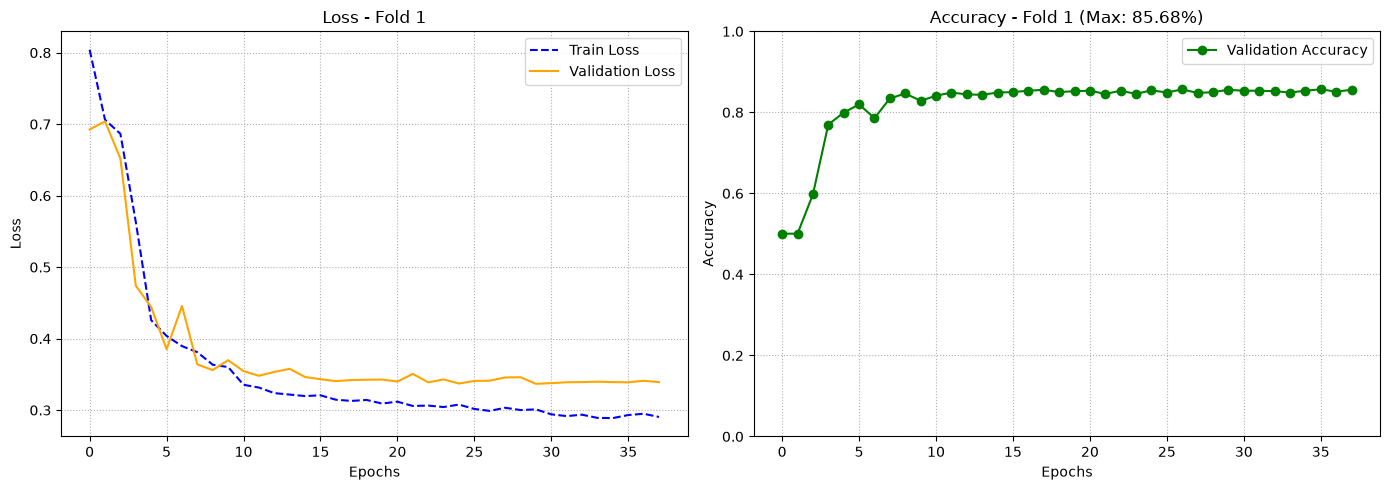

START TRAINING AND VALIDAZIONE - FOLD 2/5 
Epoch 01/50: train_loss=0.77802, train_acc=51.37%, val_loss=0.70374, val_acc=50.12% | LR: 0.001000
Epoch 02/50: train_loss=0.69553, train_acc=52.17%, val_loss=0.68401, val_acc=52.09% | LR: 0.001000
Epoch 03/50: train_loss=0.60142, train_acc=66.32%, val_loss=0.41486, val_acc=78.95% | LR: 0.001000
Epoch 04/50: train_loss=0.44875, train_acc=77.72%, val_loss=0.40415, val_acc=79.07% | LR: 0.001000
Epoch 05/50: train_loss=0.41293, train_acc=80.34%, val_loss=0.30568, val_acc=85.70% | LR: 0.001000
Epoch 06/50: train_loss=0.41444, train_acc=79.86%, val_loss=0.32393, val_acc=83.14% | LR: 0.001000
Epoch 07/50: train_loss=0.38433, train_acc=82.36%, val_loss=0.32044, val_acc=83.95% | LR: 0.001000
Epoch 08/50: train_loss=0.37237, train_acc=83.11%, val_loss=0.28221, val_acc=85.12% | LR: 0.001000
Epoch 09/50: train_loss=0.36389, train_acc=83.45%, val_loss=0.25660, val_acc=87.21% | LR: 0.001000
Epoch 10/50: train_loss=0.35637, train_acc=83.85%, val_loss=0.2622

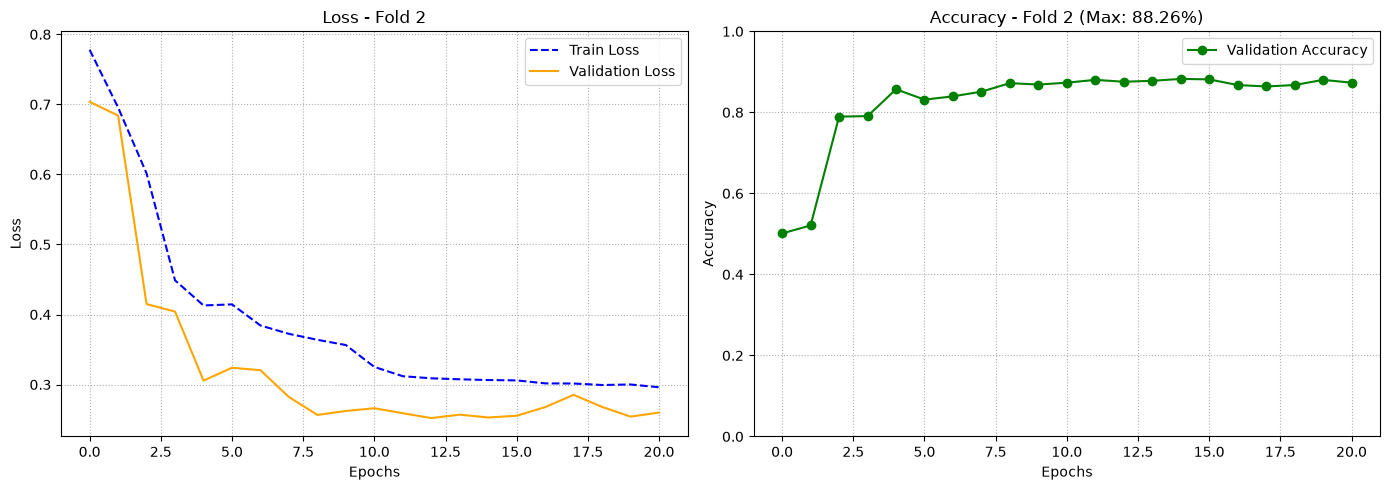

START TRAINING AND VALIDAZIONE - FOLD 3/5 
Epoch 01/50: train_loss=0.78881, train_acc=49.36%, val_loss=0.71439, val_acc=49.48% | LR: 0.001000
Epoch 02/50: train_loss=0.70010, train_acc=51.78%, val_loss=0.69437, val_acc=49.48% | LR: 0.001000
Epoch 03/50: train_loss=0.68708, train_acc=54.37%, val_loss=0.67735, val_acc=50.99% | LR: 0.001000
Epoch 04/50: train_loss=0.52866, train_acc=73.91%, val_loss=0.37810, val_acc=80.91% | LR: 0.001000
Epoch 05/50: train_loss=0.41867, train_acc=79.95%, val_loss=0.39163, val_acc=82.65% | LR: 0.001000
Epoch 06/50: train_loss=0.39797, train_acc=81.40%, val_loss=0.34756, val_acc=85.80% | LR: 0.001000
Epoch 07/50: train_loss=0.39621, train_acc=81.49%, val_loss=0.35651, val_acc=85.22% | LR: 0.001000
Epoch 08/50: train_loss=0.38789, train_acc=82.28%, val_loss=0.31513, val_acc=86.15% | LR: 0.001000
Epoch 09/50: train_loss=0.37138, train_acc=82.83%, val_loss=0.32163, val_acc=86.15% | LR: 0.001000
Epoch 10/50: train_loss=0.36560, train_acc=83.40%, val_loss=0.3449

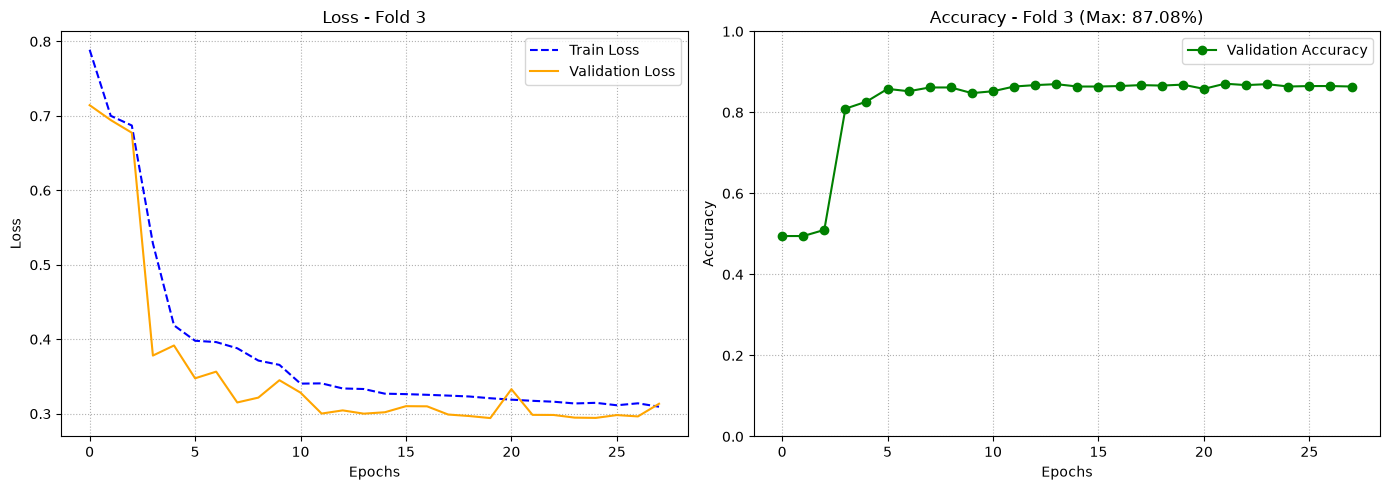

START TRAINING AND VALIDAZIONE - FOLD 4/5 
Epoch 01/50: train_loss=0.75269, train_acc=50.53%, val_loss=0.71065, val_acc=49.49% | LR: 0.001000
Epoch 02/50: train_loss=0.69488, train_acc=53.91%, val_loss=0.64496, val_acc=66.97% | LR: 0.001000
Epoch 03/50: train_loss=0.51667, train_acc=76.93%, val_loss=0.46938, val_acc=78.66% | LR: 0.001000
Epoch 04/50: train_loss=0.40934, train_acc=81.17%, val_loss=0.47648, val_acc=79.23% | LR: 0.001000
Epoch 05/50: train_loss=0.39470, train_acc=81.00%, val_loss=0.51509, val_acc=76.62% | LR: 0.001000
Epoch 06/50: train_loss=0.35619, train_acc=83.23%, val_loss=0.48657, val_acc=79.91% | LR: 0.001000
Epoch 07/50: train_loss=0.34939, train_acc=83.86%, val_loss=0.42429, val_acc=80.70% | LR: 0.001000
Epoch 08/50: train_loss=0.34973, train_acc=84.64%, val_loss=0.46331, val_acc=79.23% | LR: 0.001000
Epoch 09/50: train_loss=0.34448, train_acc=83.86%, val_loss=0.44809, val_acc=81.16% | LR: 0.001000
Epoch 10/50: train_loss=0.31818, train_acc=85.64%, val_loss=0.4288

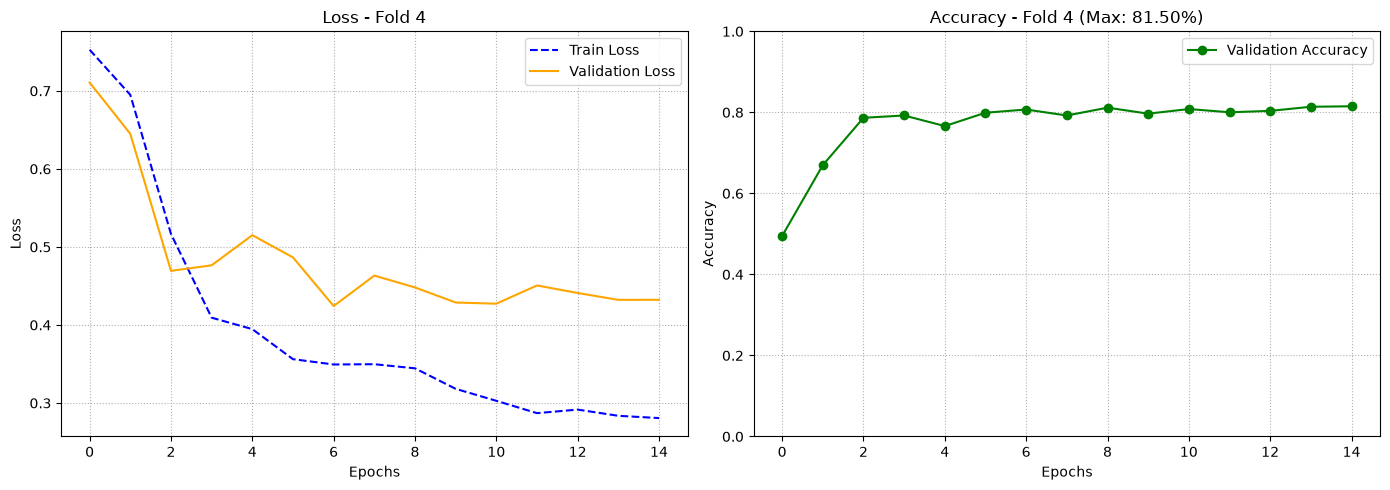

START TRAINING AND VALIDAZIONE - FOLD 5/5 
Epoch 01/50: train_loss=0.75628, train_acc=52.28%, val_loss=0.68581, val_acc=50.17% | LR: 0.001000
Epoch 02/50: train_loss=0.56276, train_acc=69.34%, val_loss=0.48858, val_acc=76.67% | LR: 0.001000
Epoch 03/50: train_loss=0.39720, train_acc=81.27%, val_loss=0.53396, val_acc=74.75% | LR: 0.001000
Epoch 04/50: train_loss=0.37461, train_acc=81.96%, val_loss=0.49365, val_acc=77.12% | LR: 0.001000
Epoch 05/50: train_loss=0.34035, train_acc=84.40%, val_loss=0.45686, val_acc=79.95% | LR: 0.001000
Epoch 06/50: train_loss=0.32721, train_acc=85.60%, val_loss=0.43782, val_acc=80.97% | LR: 0.001000
Epoch 07/50: train_loss=0.30651, train_acc=85.95%, val_loss=0.44097, val_acc=80.29% | LR: 0.001000
Epoch 08/50: train_loss=0.31201, train_acc=85.78%, val_loss=0.51639, val_acc=76.67% | LR: 0.001000
Epoch 09/50: train_loss=0.29262, train_acc=87.04%, val_loss=0.42635, val_acc=80.86% | LR: 0.001000
Epoch 10/50: train_loss=0.28426, train_acc=87.47%, val_loss=0.4437

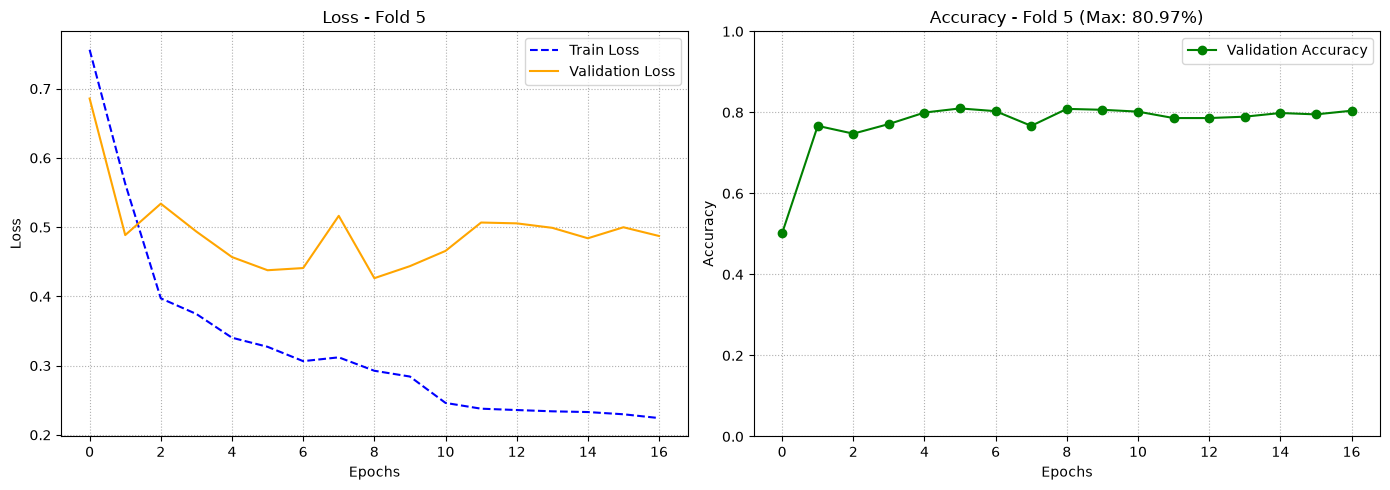

 TRAINING COMPLETED ON ALL FOLDS!
 Mean cross-validation accuracy: 84.70% (± 2.95%)
 All fold weights have been saved in the folder: '/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/notebook/train_val_F_CTrans'


In [29]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from pathlib import Path  

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50          
LR = 0.001       
WEIGHT_DECAY = 0.001 
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

models_dir = Path("train_val_F_CTrans")
models_dir.mkdir(parents=True, exist_ok=True)

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)

    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)

    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, patience = 8 , scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

   
    checkpoint = {
        'fold': fold + 1,
        'model_state_dict': model.state_dict(),
        'best_val_acc': best_val_acc,
        'train_mean': train_mean,  
        'train_std': train_std,
        'hyperparameters': {
            'num_channels': 64,
            'd_model': 128,
            'nhead': 8,
            'd_ff': 512,
            'dropout': 0.3,
            'num_layers': 3,
            'num_classes': 2,
            'lr': LR,
            'weight_decay': WEIGHT_DECAY
        }
    }

    fold_model_path = models_dir / f"f_ctrans_fold_{fold + 1}.pth"
    torch.save(checkpoint, fold_model_path)
    print(f"Fold {fold + 1} weights saved to: {fold_model_path}")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()
        
        best_global_path = models_dir / "_f_ctrans.pth"
        torch.save(checkpoint, best_global_path)
        print(f" New global record! Saved the absolute best model to: {best_global_path}")

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
print(f" TRAINING COMPLETED ON ALL FOLDS!")
print(f" Mean cross-validation accuracy: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")
print(f" All fold weights have been saved in the folder: '{models_dir.resolve()}'")

# test


In [30]:
import torch
import torch.nn.functional as F
import numpy as np
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")



models_dir = Path("train_val_F_CTrans")
models_dir.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64
EPSILON = 1e-8

all_fold_probabilities = []

for fold in range(1, 6):
    model_path = models_dir / f"f_ctrans_fold_{fold}.pth"
    print(f" [Fold {fold}/5] Processing with model: {model_path.name}")

    
    checkpoint = torch.load(model_path, map_location='cpu',weights_only=False)
    
    model_state_dict = checkpoint['model_state_dict']
    train_mean = checkpoint['train_mean']
    train_std = checkpoint['train_std']
    hp = checkpoint['hyperparameters']
    
    model = F_CTrans( num_channels=hp['num_channels'],d_model=hp['d_model'], nhead=hp['nhead'], d_ff=hp['d_ff'], dropout=hp['dropout'], num_layers=hp['num_layers'], num_classes=hp['num_classes']).to(device)
    
    model.load_state_dict(model_state_dict)
    model.eval()
    
    X_test_norm = (X_test_raw - train_mean) / (train_std + EPSILON)
    
    test_dataset = EEGDataset(X_test_norm, y_test)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    fold_probs = []
    with torch.no_grad(): 
        for x_batch, _ in test_loader:
            x_batch = x_batch.to(device)
            
            outputs = model(x_batch) 
            
            if isinstance(outputs, tuple):
                outputs = outputs[0]
                
            probs = F.softmax(outputs, dim=1)
            fold_probs.append(probs.cpu().numpy())
            
    fold_probs = np.concatenate(fold_probs, axis=0)
    all_fold_probabilities.append(fold_probs)
    print(f" [Fold {fold}] Completed.")


print(" Calculating Ensemble (Averaging probabilities across the 5 models)")
# Average along the folds axis (axis 0)
ensemble_probs = np.mean(all_fold_probabilities, axis=0)

# Select the final class with the highest average probability (Argmax)
y_pred_ensemble = np.argmax(ensemble_probs, axis=1)

final_accuracy = accuracy_score(y_test, y_pred_ensemble)


print(f" FINAL TEST SET RESULT (5-FOLD ENSEMBLE):")
print(f"Test Accuracy: {final_accuracy * 100:.2f}%")

output_path = models_dir / "test_predictions.npz"
np.savez(output_path, y_true=y_test, y_pred=y_pred_ensemble, ensemble_probs=ensemble_probs)
print(f" Results  saved to: {output_path}")


 Detected device: GPU NVIDIA (CUDA)
 [Fold 1/5] Processing with model: f_ctrans_fold_1.pth
 [Fold 1] Completed.
 [Fold 2/5] Processing with model: f_ctrans_fold_2.pth
 [Fold 2] Completed.
 [Fold 3/5] Processing with model: f_ctrans_fold_3.pth
 [Fold 3] Completed.
 [Fold 4/5] Processing with model: f_ctrans_fold_4.pth
 [Fold 4] Completed.
 [Fold 5/5] Processing with model: f_ctrans_fold_5.pth
 [Fold 5] Completed.
 Calculating Ensemble (Averaging probabilities across the 5 models)
 FINAL TEST SET RESULT (5-FOLD ENSEMBLE):
Test Accuracy: 81.41%
 Results  saved to: train_val_F_CTrans/test_predictions.npz


# 3. Faccio a modo fctrans

 Detected device: GPU NVIDIA (CUDA)
START TRAINING AND VALIDAZIONE - FOLD 1/5 
Epoch 01/50: train_loss=0.75560, train_acc=48.12%, val_loss=0.69479, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.53026, train_acc=71.40%, val_loss=0.43020, val_acc=79.03% | LR: 0.001000
Epoch 03/50: train_loss=0.41618, train_acc=80.16%, val_loss=0.42039, val_acc=80.27% | LR: 0.001000
Epoch 04/50: train_loss=0.37121, train_acc=81.74%, val_loss=0.35312, val_acc=85.01% | LR: 0.001000
Epoch 05/50: train_loss=0.34747, train_acc=83.86%, val_loss=0.35817, val_acc=83.54% | LR: 0.001000
Epoch 06/50: train_loss=0.31517, train_acc=85.41%, val_loss=0.33950, val_acc=84.22% | LR: 0.001000
Epoch 07/50: train_loss=0.30816, train_acc=86.13%, val_loss=0.35768, val_acc=83.77% | LR: 0.001000
Epoch 08/50: train_loss=0.29656, train_acc=85.53%, val_loss=0.37289, val_acc=82.41% | LR: 0.001000
Epoch 09/50: train_loss=0.31282, train_acc=85.73%, val_loss=0.33700, val_acc=83.77% | LR: 0.001000
Epoch 10/50: train_loss=0.2931

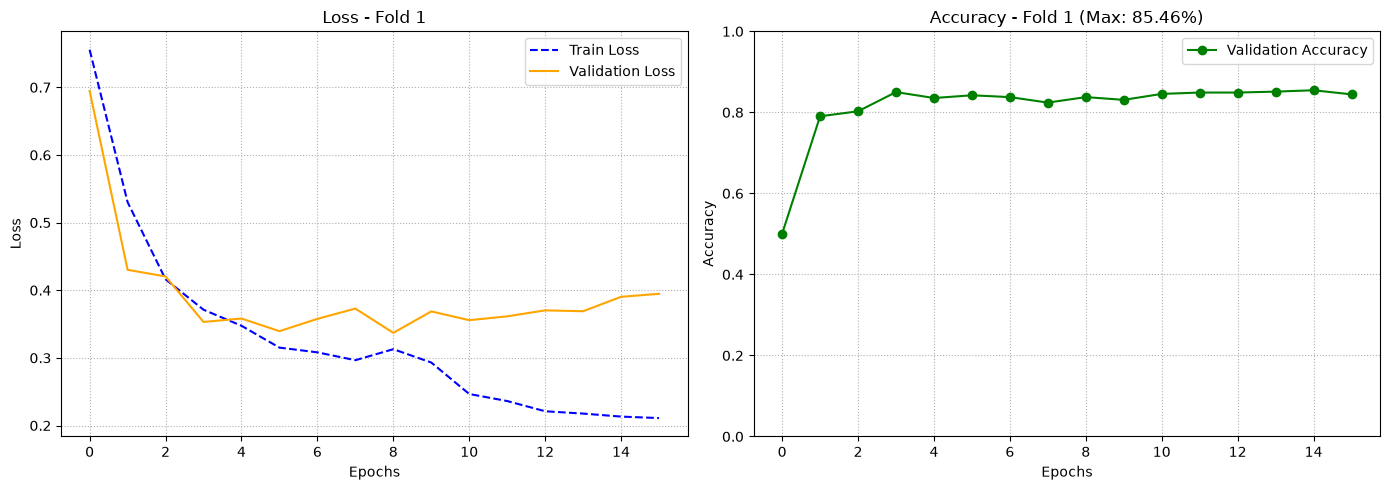

START TRAINING AND VALIDAZIONE - FOLD 2/5 
Epoch 01/50: train_loss=0.77990, train_acc=50.40%, val_loss=0.70444, val_acc=49.88% | LR: 0.001000
Epoch 02/50: train_loss=0.64445, train_acc=60.88%, val_loss=0.41630, val_acc=79.53% | LR: 0.001000
Epoch 03/50: train_loss=0.46029, train_acc=77.26%, val_loss=0.32682, val_acc=83.26% | LR: 0.001000
Epoch 04/50: train_loss=0.40954, train_acc=80.51%, val_loss=0.32837, val_acc=83.37% | LR: 0.001000
Epoch 05/50: train_loss=0.40099, train_acc=80.91%, val_loss=0.29394, val_acc=84.42% | LR: 0.001000
Epoch 06/50: train_loss=0.35705, train_acc=83.76%, val_loss=0.31889, val_acc=84.88% | LR: 0.001000
Epoch 07/50: train_loss=0.34864, train_acc=83.96%, val_loss=0.26509, val_acc=86.74% | LR: 0.001000
Epoch 08/50: train_loss=0.35413, train_acc=83.87%, val_loss=0.25499, val_acc=87.44% | LR: 0.001000
Epoch 09/50: train_loss=0.34005, train_acc=84.53%, val_loss=0.26458, val_acc=87.09% | LR: 0.001000
Epoch 10/50: train_loss=0.30609, train_acc=86.32%, val_loss=0.2584

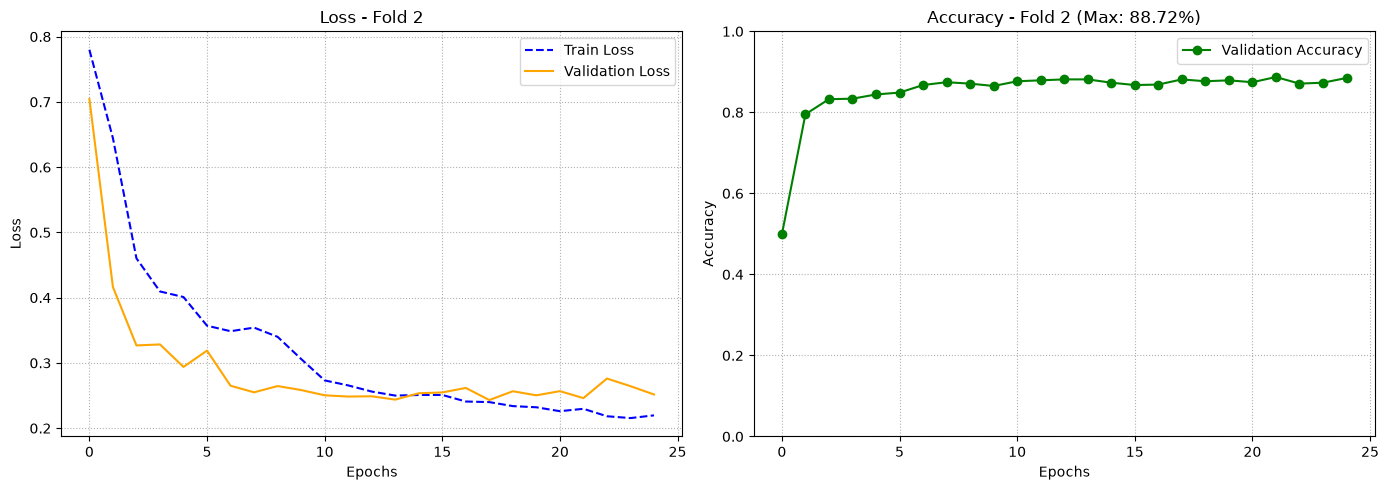

START TRAINING AND VALIDAZIONE - FOLD 3/5 
Epoch 01/50: train_loss=0.80833, train_acc=50.44%, val_loss=0.70801, val_acc=49.48% | LR: 0.001000
Epoch 02/50: train_loss=0.68597, train_acc=52.44%, val_loss=0.53349, val_acc=74.51% | LR: 0.001000
Epoch 03/50: train_loss=0.50888, train_acc=73.65%, val_loss=0.44551, val_acc=78.58% | LR: 0.001000
Epoch 04/50: train_loss=0.42892, train_acc=79.18%, val_loss=0.34913, val_acc=84.75% | LR: 0.001000
Epoch 05/50: train_loss=0.38476, train_acc=81.46%, val_loss=0.31105, val_acc=84.40% | LR: 0.001000
Epoch 06/50: train_loss=0.36515, train_acc=83.17%, val_loss=0.30225, val_acc=86.38% | LR: 0.001000
Epoch 07/50: train_loss=0.35525, train_acc=83.28%, val_loss=0.34555, val_acc=83.70% | LR: 0.001000
Epoch 08/50: train_loss=0.35052, train_acc=83.65%, val_loss=0.30214, val_acc=86.38% | LR: 0.001000
Epoch 09/50: train_loss=0.34187, train_acc=83.57%, val_loss=0.37870, val_acc=81.61% | LR: 0.001000
Epoch 10/50: train_loss=0.32564, train_acc=85.02%, val_loss=0.3056

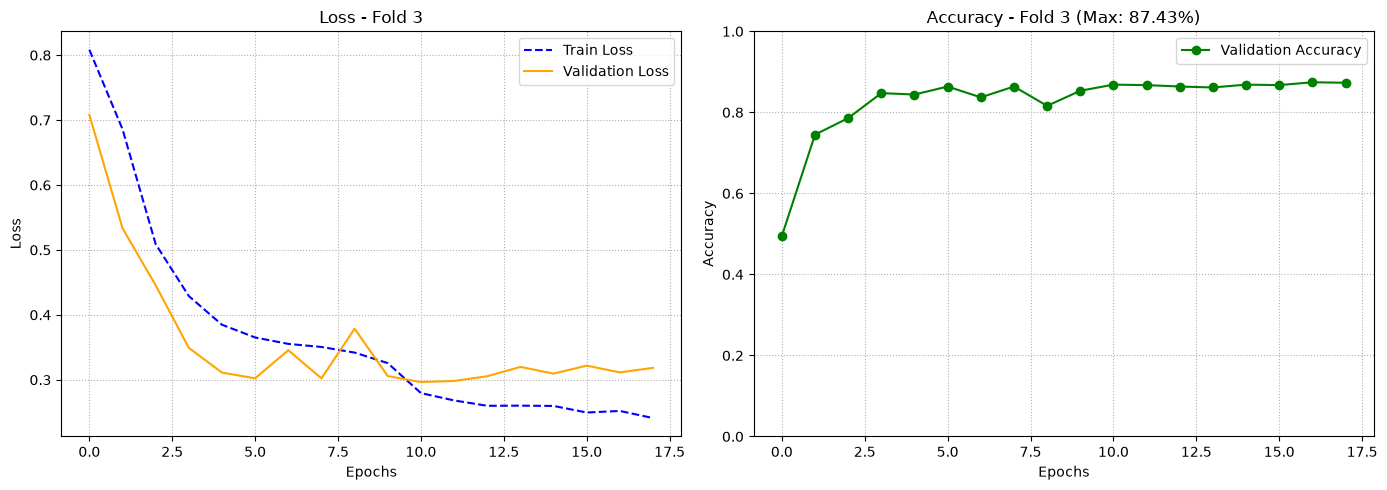

START TRAINING AND VALIDAZIONE - FOLD 4/5 
Epoch 01/50: train_loss=0.77184, train_acc=50.73%, val_loss=0.69185, val_acc=50.51% | LR: 0.001000
Epoch 02/50: train_loss=0.64223, train_acc=57.95%, val_loss=0.50012, val_acc=77.87% | LR: 0.001000
Epoch 03/50: train_loss=0.41923, train_acc=79.51%, val_loss=0.49993, val_acc=77.19% | LR: 0.001000
Epoch 04/50: train_loss=0.37228, train_acc=81.97%, val_loss=0.46147, val_acc=78.21% | LR: 0.001000
Epoch 05/50: train_loss=0.34750, train_acc=83.20%, val_loss=0.49268, val_acc=79.00% | LR: 0.001000
Epoch 06/50: train_loss=0.32509, train_acc=84.78%, val_loss=0.48367, val_acc=77.87% | LR: 0.001000
Epoch 07/50: train_loss=0.31203, train_acc=85.96%, val_loss=0.44017, val_acc=79.11% | LR: 0.001000
Epoch 08/50: train_loss=0.30017, train_acc=85.98%, val_loss=0.42186, val_acc=80.14% | LR: 0.001000
Epoch 09/50: train_loss=0.29742, train_acc=86.19%, val_loss=0.48999, val_acc=78.43% | LR: 0.001000
Epoch 10/50: train_loss=0.29199, train_acc=86.41%, val_loss=0.4907

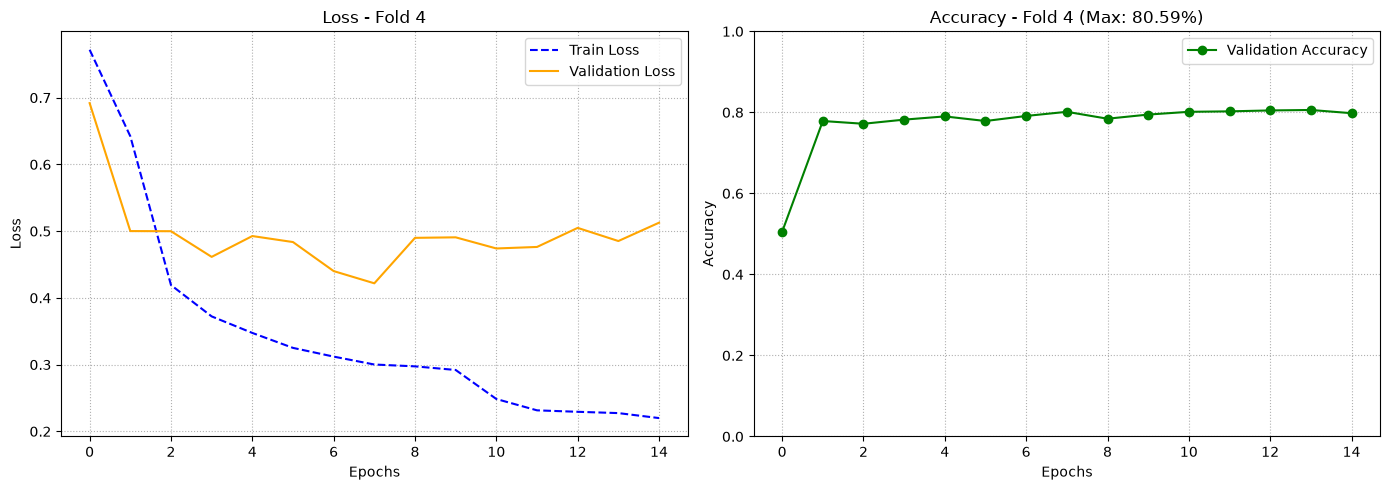

START TRAINING AND VALIDAZIONE - FOLD 5/5 
Epoch 01/50: train_loss=0.78483, train_acc=49.73%, val_loss=0.69442, val_acc=48.92% | LR: 0.001000
Epoch 02/50: train_loss=0.66356, train_acc=55.49%, val_loss=0.56703, val_acc=70.44% | LR: 0.001000
Epoch 03/50: train_loss=0.46881, train_acc=76.91%, val_loss=0.50290, val_acc=74.63% | LR: 0.001000
Epoch 04/50: train_loss=0.38734, train_acc=82.19%, val_loss=0.58087, val_acc=74.18% | LR: 0.001000
Epoch 05/50: train_loss=0.34996, train_acc=84.28%, val_loss=0.46682, val_acc=77.35% | LR: 0.001000
Epoch 06/50: train_loss=0.34338, train_acc=84.06%, val_loss=0.45910, val_acc=79.39% | LR: 0.001000
Epoch 07/50: train_loss=0.31848, train_acc=85.23%, val_loss=0.47134, val_acc=79.28% | LR: 0.001000
Epoch 08/50: train_loss=0.30134, train_acc=86.44%, val_loss=0.49412, val_acc=79.05% | LR: 0.001000
Epoch 09/50: train_loss=0.30553, train_acc=86.12%, val_loss=0.41961, val_acc=81.54% | LR: 0.001000
Epoch 10/50: train_loss=0.27864, train_acc=87.61%, val_loss=0.4422

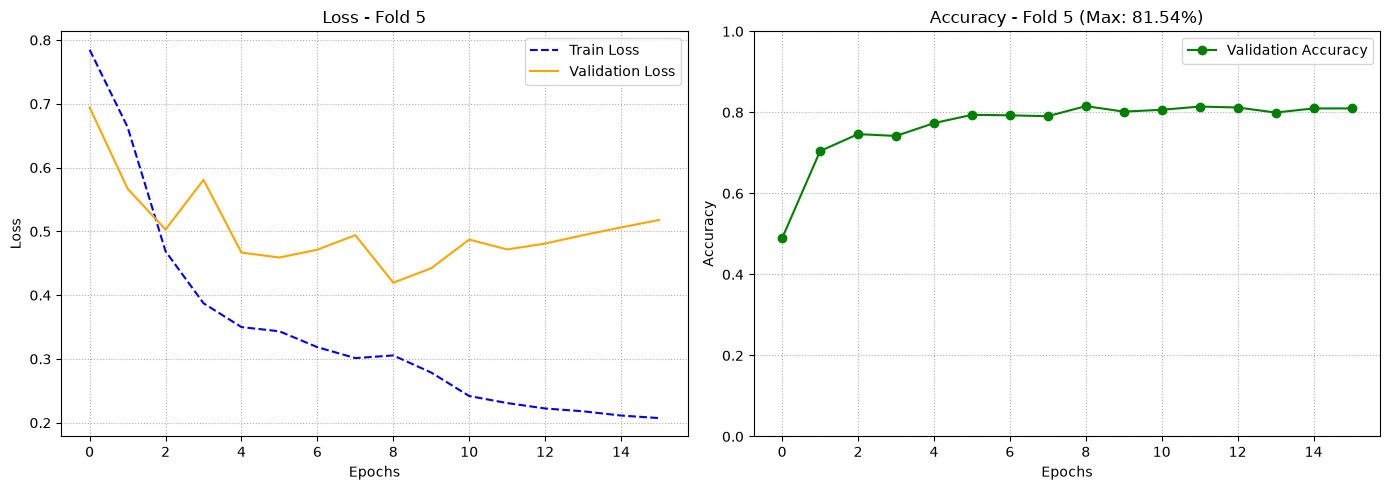

 TRAINING COMPLETED ON ALL FOLDS!
 Mean cross-validation accuracy: 84.75% (± 3.20%)
 All fold weights have been saved in the folder: '/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/notebook/F_CTrans_model'


In [12]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from pathlib import Path  

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50          
LR = 0.001       
WEIGHT_DECAY = 0.0001 
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

models_dir = Path("F_CTrans_model")
models_dir.mkdir(parents=True, exist_ok=True)

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)

    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)

    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, patience = 7 , scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

   
    checkpoint = {
        'fold': fold + 1,
        'model_state_dict': model.state_dict(),
        'best_val_acc': best_val_acc,
        'train_mean': train_mean,  
        'train_std': train_std,
        'hyperparameters': {
            'num_channels': 64,
            'd_model': 128,
            'nhead': 8,
            'd_ff': 512,
            'dropout': 0.4,
            'num_layers': 2,
            'num_classes': 2,
            'lr': LR,
            'weight_decay': WEIGHT_DECAY
        }
    }

    fold_model_path = models_dir / f"f_ctrans_fold_{fold + 1}.pth"
    torch.save(checkpoint, fold_model_path)
    print(f"Fold {fold + 1} weights saved to: {fold_model_path}")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()
        
        best_global_path = models_dir / "_f_ctrans.pth"
        torch.save(checkpoint, best_global_path)
        print(f" New global record! Saved the absolute best model to: {best_global_path}")

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
print(f" TRAINING COMPLETED ON ALL FOLDS!")
print(f" Mean cross-validation accuracy: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")
print(f" All fold weights have been saved in the folder: '{models_dir.resolve()}'")

 Detected device: GPU NVIDIA (CUDA)
START TRAINING AND VALIDAZIONE - FOLD 1/5 
Epoch 01/50: train_loss=0.75700, train_acc=51.36%, val_loss=0.69678, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.54485, train_acc=68.56%, val_loss=0.57285, val_acc=73.28% | LR: 0.001000
Epoch 03/50: train_loss=0.41986, train_acc=79.73%, val_loss=0.37366, val_acc=83.77% | LR: 0.001000
Epoch 04/50: train_loss=0.36327, train_acc=82.66%, val_loss=0.46126, val_acc=78.92% | LR: 0.001000
Epoch 05/50: train_loss=0.37746, train_acc=81.71%, val_loss=0.35132, val_acc=84.44% | LR: 0.001000
Epoch 06/50: train_loss=0.33313, train_acc=84.09%, val_loss=0.36844, val_acc=83.77% | LR: 0.001000
Epoch 07/50: train_loss=0.32047, train_acc=85.27%, val_loss=0.37690, val_acc=84.67% | LR: 0.001000
Epoch 08/50: train_loss=0.31504, train_acc=85.64%, val_loss=0.36416, val_acc=84.10% | LR: 0.001000
Epoch 09/50: train_loss=0.29708, train_acc=86.62%, val_loss=0.39856, val_acc=82.30% | LR: 0.001000
Epoch 10/50: train_loss=0.2958

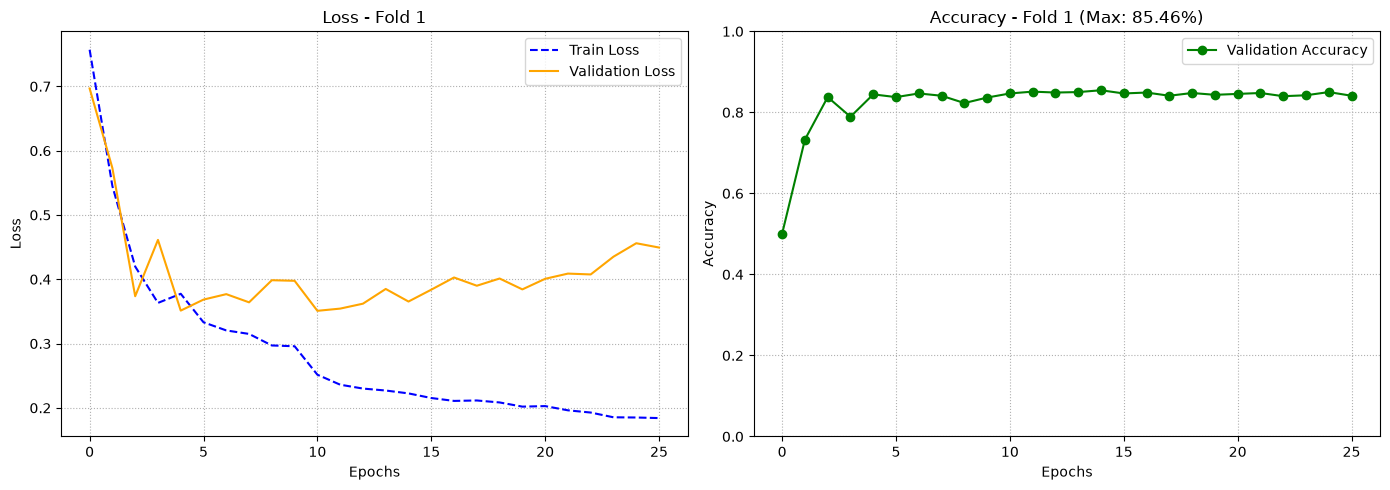

START TRAINING AND VALIDAZIONE - FOLD 2/5 
Epoch 01/50: train_loss=0.78065, train_acc=50.68%, val_loss=0.69654, val_acc=50.12% | LR: 0.001000
Epoch 02/50: train_loss=0.68781, train_acc=52.51%, val_loss=0.50900, val_acc=77.91% | LR: 0.001000
Epoch 03/50: train_loss=0.47437, train_acc=76.44%, val_loss=0.35380, val_acc=80.35% | LR: 0.001000
Epoch 04/50: train_loss=0.42654, train_acc=79.32%, val_loss=0.32677, val_acc=82.67% | LR: 0.001000
Epoch 05/50: train_loss=0.37224, train_acc=82.36%, val_loss=0.28184, val_acc=85.12% | LR: 0.001000
Epoch 06/50: train_loss=0.37043, train_acc=82.22%, val_loss=0.28615, val_acc=87.09% | LR: 0.001000
Epoch 07/50: train_loss=0.34083, train_acc=84.90%, val_loss=0.26788, val_acc=86.51% | LR: 0.001000
Epoch 08/50: train_loss=0.34526, train_acc=84.05%, val_loss=0.29405, val_acc=84.42% | LR: 0.001000
Epoch 09/50: train_loss=0.31011, train_acc=86.41%, val_loss=0.25707, val_acc=87.56% | LR: 0.001000
Epoch 10/50: train_loss=0.30610, train_acc=86.52%, val_loss=0.2853

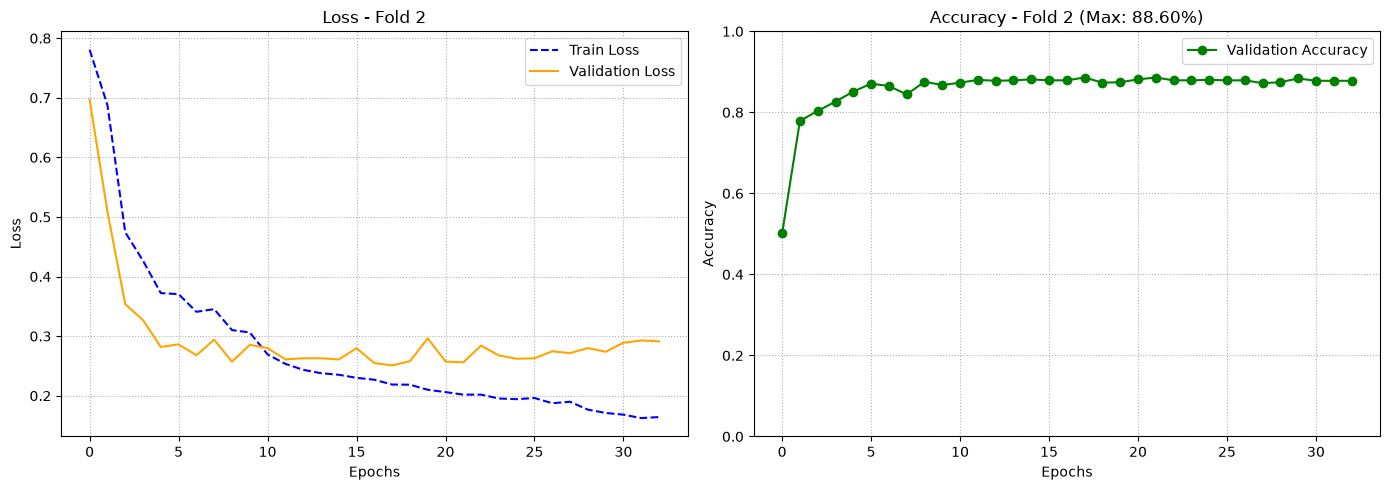

START TRAINING AND VALIDAZIONE - FOLD 3/5 
Epoch 01/50: train_loss=0.74122, train_acc=51.18%, val_loss=0.68033, val_acc=50.76% | LR: 0.001000
Epoch 02/50: train_loss=0.57163, train_acc=67.84%, val_loss=0.35704, val_acc=83.35% | LR: 0.001000
Epoch 03/50: train_loss=0.42272, train_acc=79.86%, val_loss=0.34759, val_acc=85.45% | LR: 0.001000
Epoch 04/50: train_loss=0.38420, train_acc=81.77%, val_loss=0.45803, val_acc=80.21% | LR: 0.001000
Epoch 05/50: train_loss=0.37281, train_acc=82.40%, val_loss=0.29460, val_acc=85.45% | LR: 0.001000
Epoch 06/50: train_loss=0.34765, train_acc=83.62%, val_loss=0.32077, val_acc=85.80% | LR: 0.001000
Epoch 07/50: train_loss=0.33220, train_acc=84.45%, val_loss=0.33061, val_acc=85.56% | LR: 0.001000
Epoch 08/50: train_loss=0.31847, train_acc=85.76%, val_loss=0.29559, val_acc=86.38% | LR: 0.001000
Epoch 09/50: train_loss=0.32207, train_acc=85.33%, val_loss=0.31156, val_acc=86.96% | LR: 0.001000
Epoch 10/50: train_loss=0.31684, train_acc=85.33%, val_loss=0.3021

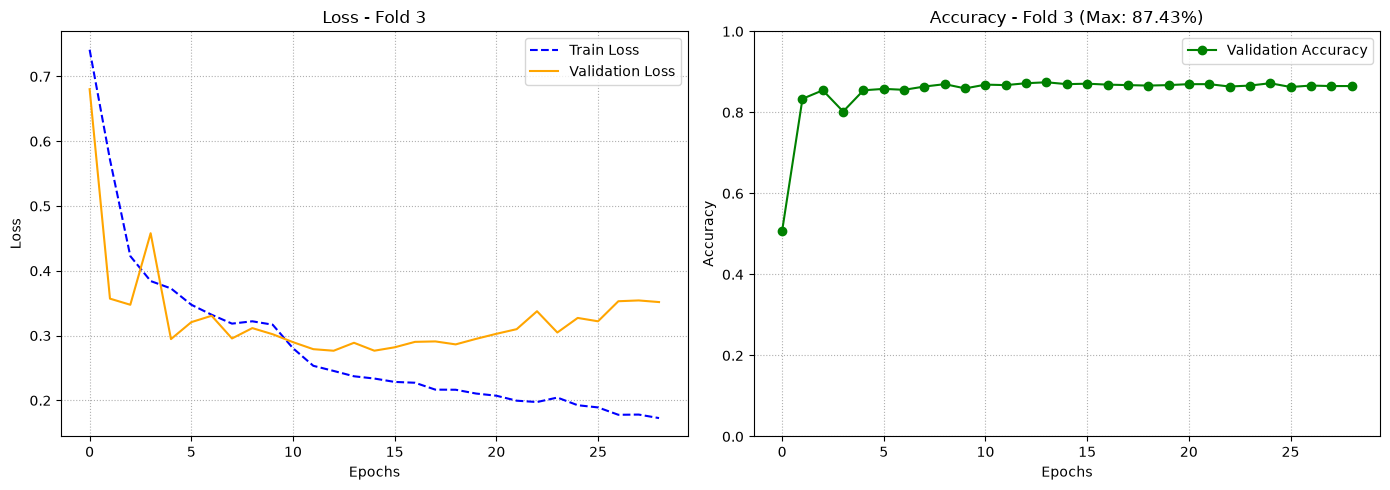

START TRAINING AND VALIDAZIONE - FOLD 4/5 
Epoch 01/50: train_loss=0.76835, train_acc=51.56%, val_loss=0.69317, val_acc=49.49% | LR: 0.001000
Epoch 02/50: train_loss=0.58119, train_acc=66.81%, val_loss=0.49704, val_acc=76.50% | LR: 0.001000
Epoch 03/50: train_loss=0.40954, train_acc=79.71%, val_loss=0.52751, val_acc=77.98% | LR: 0.001000
Epoch 04/50: train_loss=0.38336, train_acc=81.11%, val_loss=0.52783, val_acc=77.41% | LR: 0.001000
Epoch 05/50: train_loss=0.35684, train_acc=82.98%, val_loss=0.44431, val_acc=80.14% | LR: 0.001000
Epoch 06/50: train_loss=0.32390, train_acc=85.10%, val_loss=0.43369, val_acc=81.38% | LR: 0.001000
Epoch 07/50: train_loss=0.35163, train_acc=83.09%, val_loss=0.44130, val_acc=79.00% | LR: 0.001000
Epoch 08/50: train_loss=0.31688, train_acc=85.70%, val_loss=0.43895, val_acc=79.91% | LR: 0.001000
Epoch 09/50: train_loss=0.30437, train_acc=84.95%, val_loss=0.44464, val_acc=79.46% | LR: 0.001000
Epoch 10/50: train_loss=0.28751, train_acc=86.56%, val_loss=0.4493

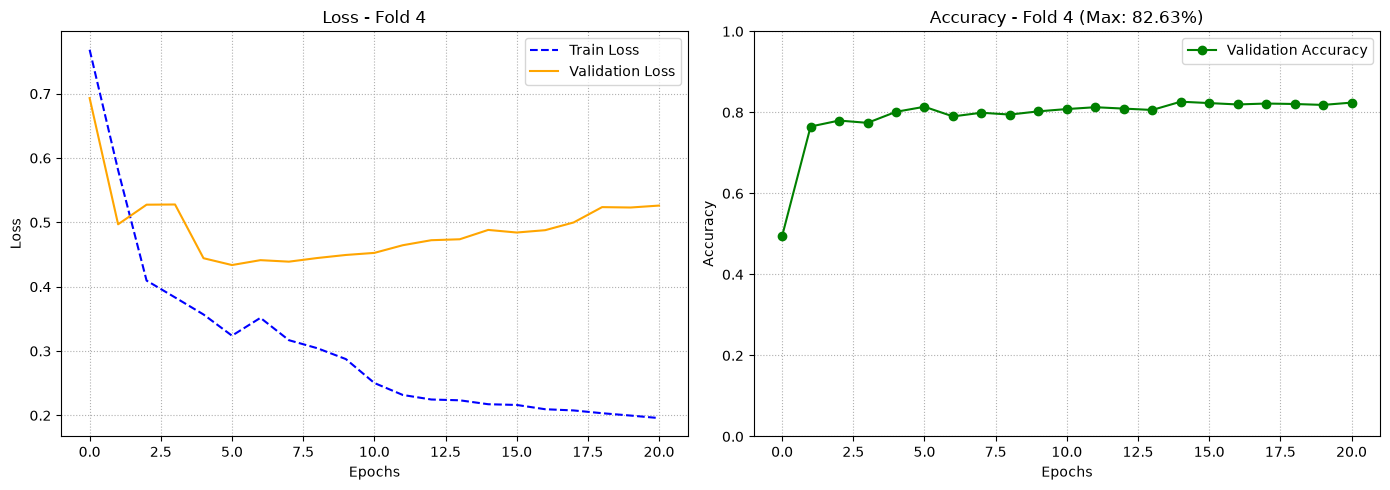

START TRAINING AND VALIDAZIONE - FOLD 5/5 
Epoch 01/50: train_loss=0.70340, train_acc=55.46%, val_loss=0.54135, val_acc=71.80% | LR: 0.001000
Epoch 02/50: train_loss=0.44310, train_acc=78.49%, val_loss=0.48956, val_acc=75.08% | LR: 0.001000
Epoch 03/50: train_loss=0.35874, train_acc=83.08%, val_loss=0.54959, val_acc=74.18% | LR: 0.001000
Epoch 04/50: train_loss=0.33716, train_acc=84.71%, val_loss=0.43405, val_acc=79.28% | LR: 0.001000
Epoch 05/50: train_loss=0.32673, train_acc=84.80%, val_loss=0.43988, val_acc=79.05% | LR: 0.001000
Epoch 06/50: train_loss=0.29382, train_acc=86.69%, val_loss=0.47080, val_acc=80.86% | LR: 0.001000
Epoch 07/50: train_loss=0.29114, train_acc=86.78%, val_loss=0.58292, val_acc=74.18% | LR: 0.001000
Epoch 08/50: train_loss=0.27244, train_acc=87.61%, val_loss=0.55507, val_acc=77.24% | LR: 0.001000
Epoch 09/50: train_loss=0.28191, train_acc=87.24%, val_loss=0.52973, val_acc=77.58% | LR: 0.001000
Epoch 10/50: train_loss=0.27774, train_acc=87.81%, val_loss=0.4590

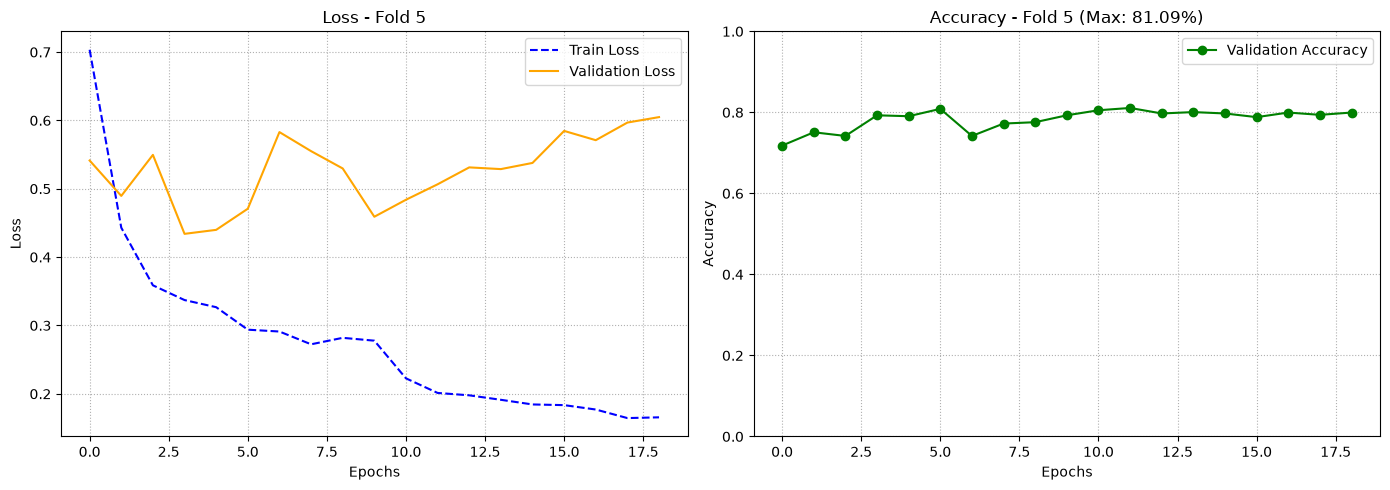

 TRAINING COMPLETED ON ALL FOLDS!
 Mean cross-validation accuracy: 85.04% (± 2.83%)
 All fold weights have been saved in the folder: '/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/notebook/model_F_CTrans'


In [13]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from pathlib import Path  

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50          
LR = 0.001       
WEIGHT_DECAY = 0.0001 
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

models_dir = Path("model_F_CTrans")
models_dir.mkdir(parents=True, exist_ok=True)

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)

    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)

    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, patience = 15 , scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

   
    checkpoint = {
        'fold': fold + 1,
        'model_state_dict': model.state_dict(),
        'best_val_acc': best_val_acc,
        'train_mean': train_mean,  
        'train_std': train_std,
        'hyperparameters': {
            'num_channels': 64,
            'd_model': 128,
            'nhead': 8,
            'd_ff': 512,
            'dropout': 0.4,
            'num_layers': 2,
            'num_classes': 2,
            'lr': LR,
            'weight_decay': WEIGHT_DECAY
        }
    }

    fold_model_path = models_dir / f"f_ctrans_fold_{fold + 1}.pth"
    torch.save(checkpoint, fold_model_path)
    print(f"Fold {fold + 1} weights saved to: {fold_model_path}")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()
        
        best_global_path = models_dir / "_f_ctrans.pth"
        torch.save(checkpoint, best_global_path)
        print(f" New global record! Saved the absolute best model to: {best_global_path}")

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
print(f" TRAINING COMPLETED ON ALL FOLDS!")
print(f" Mean cross-validation accuracy: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")
print(f" All fold weights have been saved in the folder: '{models_dir.resolve()}'")

In [14]:
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    # SALTA TUTTI I FOLD TRANNE IL QUINTO (indice 4)
    if fold != 4:
        continue
    
    print(f"START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)

    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)

    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, patience = 50 , scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

   
    checkpoint = {
        'fold': fold + 1,
        'model_state_dict': model.state_dict(),
        'best_val_acc': best_val_acc,
        'train_mean': train_mean,  
        'train_std': train_std,
        'hyperparameters': {
            'num_channels': 64,
            'd_model': 128,
            'nhead': 8,
            'd_ff': 512,
            'dropout': 0.4,
            'num_layers': 2,
            'num_classes': 2,
            'lr': LR,
            'weight_decay': WEIGHT_DECAY
        }
    }

    fold_model_path = models_dir / f"f_ctrans_fold_{fold + 1}_patience50.pth"
    torch.save(checkpoint, fold_model_path)
    print(f"Fold {fold + 1} weights saved to: {fold_model_path}")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()
        
        best_global_path = models_dir / "_f_ctrans.pth"
        torch.save(checkpoint, best_global_path)
        print(f" New global record! Saved the absolute best model to: {best_global_path}")

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
print(f" TRAINING COMPLETED FOR FOLD 5!")
print(f" Fold 5 accuracy: {fold_accuracies[0]*100:.2f}%")
print(f" Weights have been saved in the folder: '{models_dir.resolve()}'")

START TRAINING AND VALIDAZIONE - FOLD 5/5 
Epoch 01/50: train_loss=0.77339, train_acc=50.73%, val_loss=0.69345, val_acc=51.08% | LR: 0.001000
Epoch 02/50: train_loss=0.59519, train_acc=64.90%, val_loss=0.57771, val_acc=73.50% | LR: 0.001000
Epoch 03/50: train_loss=0.40431, train_acc=80.99%, val_loss=0.50589, val_acc=75.65% | LR: 0.001000
Epoch 04/50: train_loss=0.35231, train_acc=83.62%, val_loss=0.46186, val_acc=77.58% | LR: 0.001000
Epoch 05/50: train_loss=0.33103, train_acc=85.43%, val_loss=0.46045, val_acc=76.78% | LR: 0.001000
Epoch 06/50: train_loss=0.31904, train_acc=84.74%, val_loss=0.46040, val_acc=79.95% | LR: 0.001000
Epoch 07/50: train_loss=0.29196, train_acc=86.35%, val_loss=0.46348, val_acc=79.28% | LR: 0.001000
Epoch 08/50: train_loss=0.29928, train_acc=85.72%, val_loss=0.48301, val_acc=79.39% | LR: 0.001000
Epoch 09/50: train_loss=0.27820, train_acc=87.15%, val_loss=0.51894, val_acc=78.03% | LR: 0.001000
Epoch 10/50: train_loss=0.27005, train_acc=87.96%, val_loss=0.6128

KeyboardInterrupt: 